# Investigating the relationships between economic statistics and gold prices in the U.S.
Rachel Leung, Jenny Xu, Zachary Loo, Shouki Katsuyama

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid", palette="pastel")

## Introduction

<img src="./data/goldbar.jpg">

## Dataset

### Gold Price

In [2]:
# Read the data
gold = pd.read_csv("./data/gold.csv")
gold = gold.rename(columns={"Price": "GoldPrice"})
# Convert Date column to datetime
gold["Date"] = pd.to_datetime(gold["Date"]).dt.to_period("M")

new_rows = pd.DataFrame([
    {"Date": pd.Period("2025-08", freq="M"), "GoldPrice": 3362.94},
    {"Date": pd.Period("2025-09", freq="M"), "GoldPrice": 3476.72},
    {"Date": pd.Period("2025-10", freq="M"), "GoldPrice": 3865.75},
    {"Date": pd.Period("2025-11", freq="M"), "GoldPrice": 4003.28},
    {"Date": pd.Period("2025-12", freq="M"), "GoldPrice": 4231.40}
])

# Concatenate the original and new DataFrames, ignoring the old index
gold = pd.concat([gold, new_rows], ignore_index=True)


# Filter for the desired date range
gold = gold[
    (gold["Date"] >= pd.Period("2000-01", freq="M")) &
    (gold["Date"] <= pd.Period("2025-12", freq="M"))
].reset_index(drop=True)

df = gold

### Unemployment Rate

In [3]:
unrate = pd.read_csv("./data/unrate.csv")
unrate = unrate.rename(columns={"unrate": "UnemploymentRate", "observation_date": "Date"})
unrate["Date"] = pd.to_datetime(unrate["Date"]).dt.to_period("M")
unrate.columns = ["Date", "UnemploymentRate"]
df = df.merge(unrate, on="Date", how="left")

### Tax Bracket Threshold

This dataset uses top marginal income tax bracket threshold (37%). Top tax bracket threshold is income level at which the highest marginal tax rate applies. Since the top marginal tax rate remained constant during the study period, we instead use top bracket threshold that vary over time to capture fiscal pressure on capital. We use the U.S. top marginal income tax rate as a proxy for fiscal pressure on capital and wealth because gold reacts much more to wealth taxation environment, capital taxation expectations, high-income marginal burden, and fiscal policy stance.  Since tax policy changes infrequently, annual rates were assigned uniformly across months.

In [4]:
tax = pd.read_csv("./data/tax.csv").dropna()
tax["Date"] = pd.to_datetime(tax["Date"], format="%m/%d/%y").dt.to_period("M")
tax.columns = ["Date", "TopTaxBracketThreshold"]
df = df.merge(tax, on="Date", how="left")

### Inflation Rate

In [5]:
# Read the data, skipping the malformed rows (2026 data)
inflation = pd.read_csv("./data/inflation.csv", sep="\t", skiprows=[1, 2, 3])

# Melt the dataframe to convert months from columns to rows
melted_df = pd.melt(inflation,
                    id_vars=["Year"],
                    value_vars=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
                    var_name="Month",
                    value_name="Value")

# Clean up the values (remove special characters like – (*) and convert to float)
melted_df["Value"] = melted_df["Value"].astype(str).str.replace("– (*)", "", regex=False)
melted_df["Value"] = melted_df["Value"].str.strip()
melted_df["Value"] = pd.to_numeric(melted_df["Value"], errors="coerce")

# Create date column (first day of each month)
month_map = {"Jan": 1, "Feb": 2, "Mar": 3, "Apr": 4, "May": 5, "Jun": 6,
             "Jul": 7, "Aug": 8, "Sep": 9, "Oct": 10, "Nov": 11, "Dec": 12}

melted_df["Month_Num"] = melted_df["Month"].map(month_map)
melted_df["Date"] = pd.to_datetime(melted_df["Year"].astype(str) + "-" +
                                   melted_df["Month_Num"].astype(str) + "-01")

# Select and sort final columns
final_df = melted_df[["Date", "Value"]].sort_values("Date").reset_index(drop=True)

# Drop rows with missing values (like the 2026 data)
inflation = final_df.dropna()
inflation = inflation.rename(columns={"Value": "InflationRate"})
inflation["Date"] = pd.to_datetime(inflation["Date"]).dt.to_period("M")
df = df.merge(inflation, on="Date", how="left")

### US Dollar Strength

In [6]:
dollar = pd.read_csv("./data/dollar.csv")
dollar["Date"] = pd.to_datetime(dollar["Date"]).dt.to_period("M")
dollar = dollar[["Date", "Price"]].rename(columns = {"Price": "USDollarIndex"})
df = df.merge(dollar, on="Date", how="left")

### Interest Rate

In [7]:
interest = pd.read_csv("./data/interest.csv")
interest = interest.rename(columns = {"observation_date": "Date"})
interest["Date"] = pd.to_datetime(interest["Date"]).dt.to_period("M")
interest = interest.rename(columns = {"REAINTRATREARAT10Y": "RealInterestRate"})
df = df.merge(interest, on="Date", how="left")

### Federal Funds Rate

In [8]:
federal = pd.read_csv("./data/dff.csv")
federal = federal.rename(columns = {"observation_date": "Date", "DFF": "FederalFundsRate"})
federal["Date"] = pd.to_datetime(federal["Date"])
federal["Date"] = federal["Date"].dt.to_period("M")
federal = federal.groupby("Date").first().reset_index()
df = df.merge(federal, on="Date", how="left")

### Treasury Yield

In [9]:
treasury = pd.read_csv("./data/treasury.csv")
treasury = treasury.rename(columns = {"observation_date": "Date", "DGS10": "TreasuryYield"})
treasury["Date"] = pd.to_datetime(treasury["Date"])
treasury["Date"] = treasury["Date"].dt.to_period("M")
treasury = treasury.groupby("Date").first().reset_index()
df = df.merge(treasury, on="Date", how="left")

### Consumer Confidence Index

In [10]:
consumer = pd.read_csv("./data/consumer.csv")
consumer = consumer.rename(columns = {"observation_date": "Date"})
consumer["Date"] = pd.to_datetime(consumer["Date"]).dt.to_period("M")
consumer = consumer.rename(columns = {"USACSCICP02STSAM": "ConsumerConfidenceIndex"})
df = df.merge(consumer, on="Date", how="left")

### Recession Indicator

In [11]:
recession = pd.read_csv("./data/recession.csv")
recession = recession.rename(columns = {"observation_date": "Date"})
recession["Date"] = pd.to_datetime(recession["Date"]).dt.to_period("M")
recession = recession.rename(columns = {"SAHMREALTIME": "RecessionIndicator"})
df = df.merge(recession, on="Date", how="left")

### Gas/Oil Price

In [12]:
gas = pd.read_csv("./data/gas.csv")
gas = gas.rename(columns = {"observation_date": "Date", "GASREGW": "GasPrice"})
gas["Date"] = pd.to_datetime(gas["Date"])
gas["Date"] = gas["Date"].dt.to_period("M")
gas = gas.groupby("Date").first().reset_index()
df = df.merge(gas, on="Date", how="left")

### Silver Price

In [13]:
silver = pd.read_csv("./data/silver.csv")
silver = silver.rename(columns={"Value": "SilverPrice"})
silver["Date"] = pd.to_datetime(silver["Date"]).dt.to_period("M")
silver = silver[
    (silver["Date"] >= pd.Period("2000-01", freq="M")) &
    (silver["Date"] <= pd.Period("2025-12", freq="M"))
]
df = df.merge(silver, on="Date", how="left")

### Filling Null Values

Here, we fill null values with the one from previous row.

In [14]:
df["Date"] = df["Date"].astype(str)
df = df.ffill().set_index("Date")
df.head(5)

,GoldPrice,UnemploymentRate,TopTaxBracketThreshold,InflationRate,USDollarIndex,RealInterestRate,FederalFundsRate,TreasuryYield,ConsumerConfidenceIndex,RecessionIndicator,GasPrice,SilverPrice
Date,,,,,,,,,,,,
2000-01,284.32,4.0,288350.0,2.7,105.13,3.411051,3.99,6.58,120.5057,-0.03,1.272,10.14
2000-02,299.86,4.1,288350.0,3.2,105.92,3.513343,5.79,6.62,119.7525,0.00,1.325,9.77
2000-03,286.39,4.0,288350.0,3.8,105.44,3.440347,5.78,6.39,115.2336,0.00,1.501,9.39
2000-04,279.69,3.8,288350.0,3.1,110.14,3.202967,6.17,6.00,117.4930,-0.03,1.503,9.38
2000-05,275.19,4.0,288350.0,3.2,108.74,3.360531,6.17,6.29,119.1070,0.00,1.420,9.29


## EDA

In [88]:
summary_stats = df.describe().T[['mean','std','min','max']]
print(summary_stats)

                                  mean           std            min  \
GoldPrice                  1222.659590    729.510304     260.480000   
UnemploymentRate              5.640385      1.942709       3.400000   
TopTaxBracketThreshold   417989.500000  98585.368819  288350.000000   
InflationRate                 2.586218      1.738010      -2.100000   
USDollarIndex                92.842083     11.381629      71.800000   
RealInterestRate              1.188509      0.848665      -0.407134   
FederalFundsRate              2.011506      2.041251       0.040000   
TreasuryYield                 3.311635      1.304137       0.560000   
ConsumerConfidenceIndex      88.113582     14.972372      53.797180   
RecessionIndicator            0.480000      1.249878      -0.370000   
GasPrice                      2.655801      0.780516       1.108000   
SilverPrice                  23.607628     11.483798       7.590000   

                                   max  
GoldPrice                  4231.400

### Lineplot

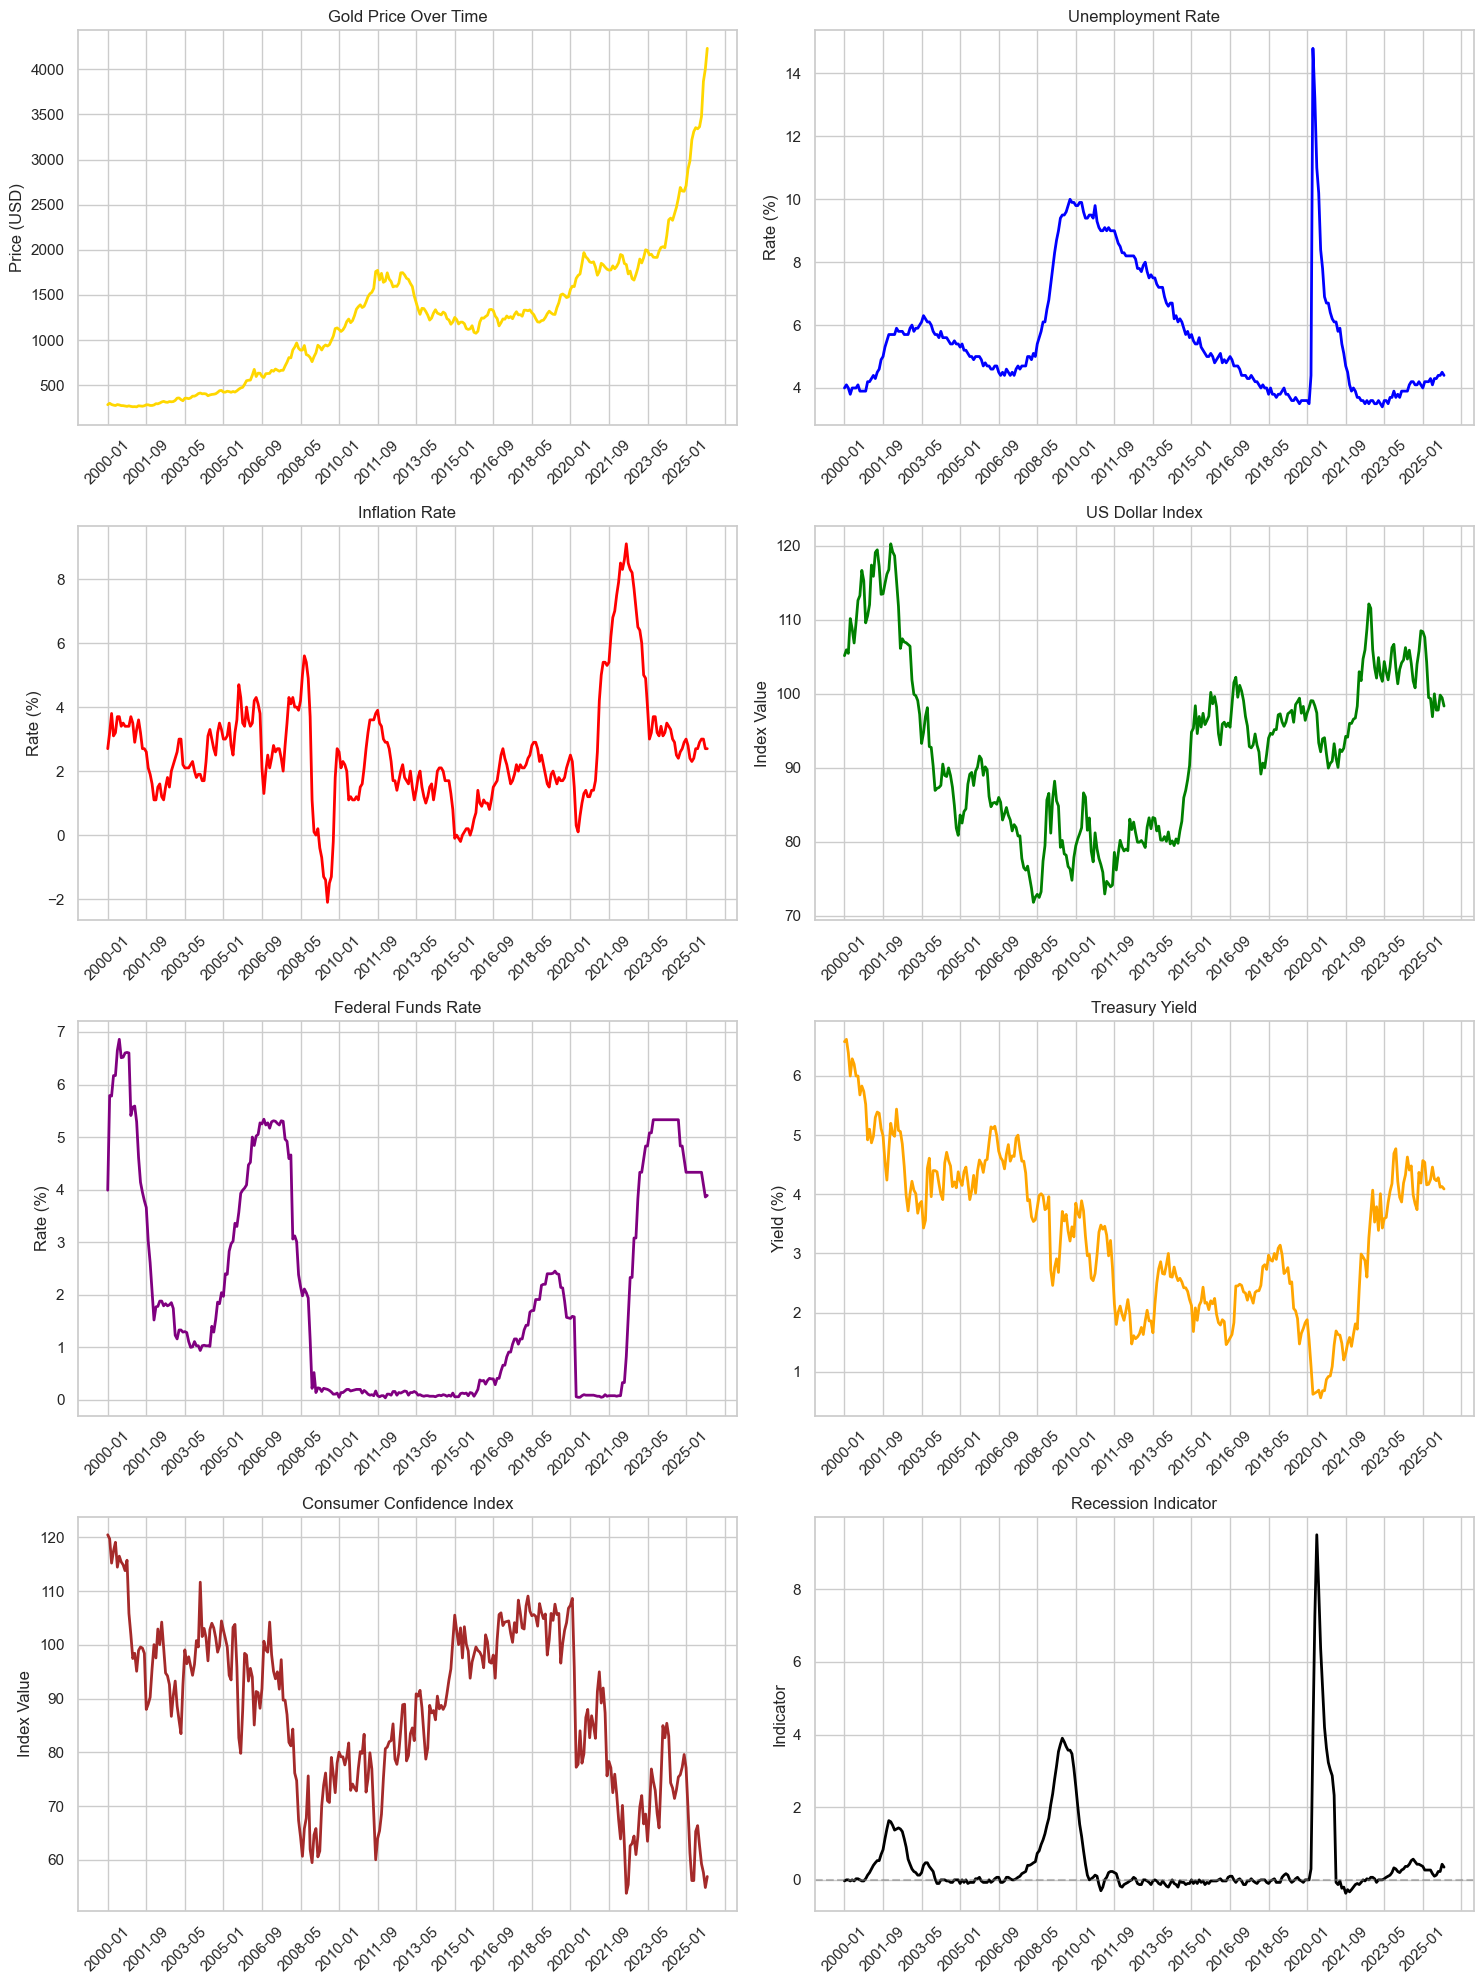

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(15, 20))
#Gold Price and Key Economic Indicators Over Time (2000-2025)

# Gold Price
axes[0, 0].plot(df.index, df["GoldPrice"], linewidth=2, color="gold")
axes[0, 0].set_title("Gold Price Over Time")
axes[0, 0].set_ylabel("Price (USD)")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].xaxis.set_major_locator(plt.MaxNLocator(20))

# Unemployment Rate
axes[0, 1].plot(df.index, df["UnemploymentRate"], linewidth=2, color="blue")
axes[0, 1].set_title("Unemployment Rate")
axes[0, 1].set_ylabel("Rate (%)")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].xaxis.set_major_locator(plt.MaxNLocator(20))

# Inflation Rate
axes[1, 0].plot(df.index, df["InflationRate"], linewidth=2, color="red")
axes[1, 0].set_title("Inflation Rate")
axes[1, 0].set_ylabel("Rate (%)")
axes[1, 0].tick_params(axis="x", rotation=45)
axes[1, 0].xaxis.set_major_locator(plt.MaxNLocator(20))

# US Dollar Index
axes[1, 1].plot(df.index, df["USDollarIndex"], linewidth=2, color="green")
axes[1, 1].set_title("US Dollar Index")
axes[1, 1].set_ylabel("Index Value")
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].xaxis.set_major_locator(plt.MaxNLocator(20))

# Federal Funds Rate
axes[2, 0].plot(df.index, df["FederalFundsRate"], linewidth=2, color="purple")
axes[2, 0].set_title("Federal Funds Rate")
axes[2, 0].set_ylabel("Rate (%)")
axes[2, 0].tick_params(axis="x", rotation=45)
axes[2, 0].xaxis.set_major_locator(plt.MaxNLocator(20))

# Treasury Yield
axes[2, 1].plot(df.index, df["TreasuryYield"], linewidth=2, color="orange")
axes[2, 1].set_title("Treasury Yield")
axes[2, 1].set_ylabel("Yield (%)")
axes[2, 1].tick_params(axis="x", rotation=45)
axes[2, 1].xaxis.set_major_locator(plt.MaxNLocator(20))

# Consumer Confidence
axes[3, 0].plot(df.index, df["ConsumerConfidenceIndex"], linewidth=2, color="brown")
axes[3, 0].set_title("Consumer Confidence Index")
axes[3, 0].set_ylabel("Index Value")
axes[3, 0].tick_params(axis="x", rotation=45)
axes[3, 0].xaxis.set_major_locator(plt.MaxNLocator(20))

# Recession Indicator
axes[3, 1].plot(df.index, df["RecessionIndicator"], linewidth=2, color="black")
axes[3, 1].set_title("Recession Indicator")
axes[3, 1].set_ylabel("Indicator")
axes[3, 1].tick_params(axis="x", rotation=45)
axes[3, 1].xaxis.set_major_locator(plt.MaxNLocator(20))
axes[3, 1].axhline(y=0, color="gray", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Histograms

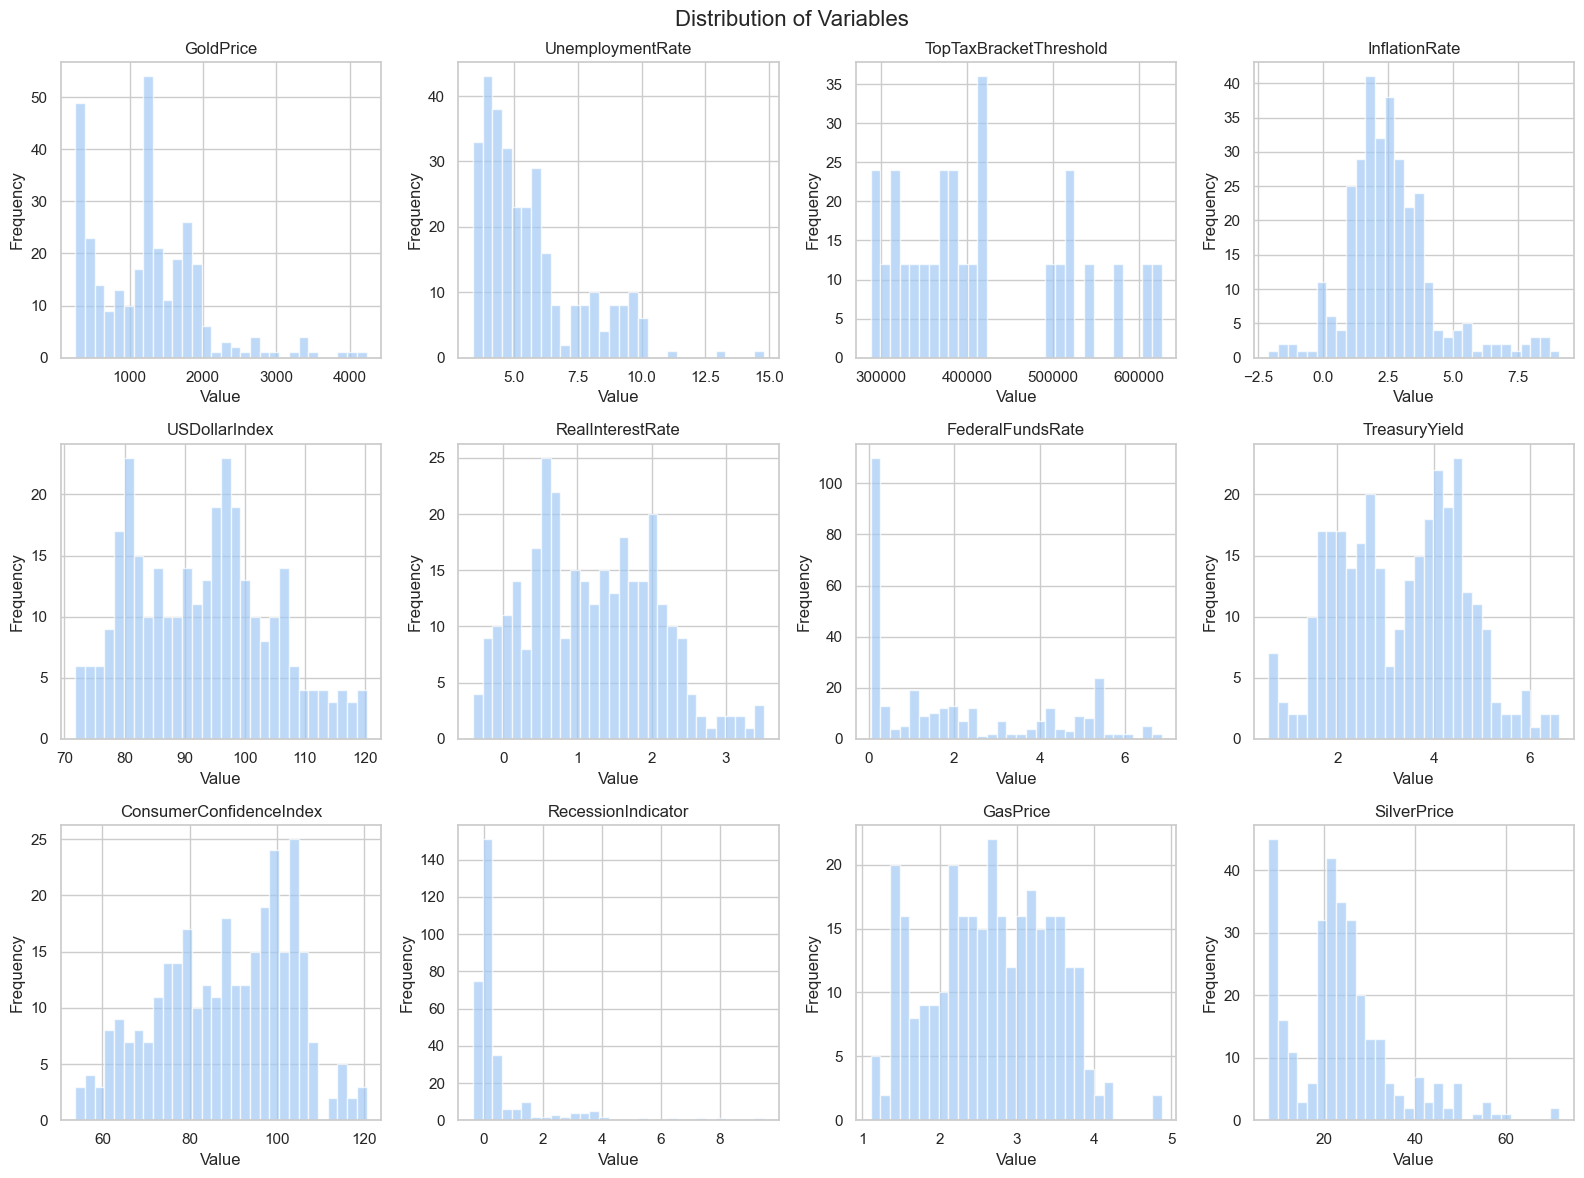

In [16]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
fig.suptitle("Distribution of Variables", fontsize=16, y=0.98)

variables = df.columns
for i, ax in enumerate(axes.flat):
    if i < len(variables):
        ax.hist(df[variables[i]].dropna(), bins=30, alpha=0.7)
        ax.set_title(variables[i])
        ax.set_xlabel("Value")
        ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### Correlation Matrix

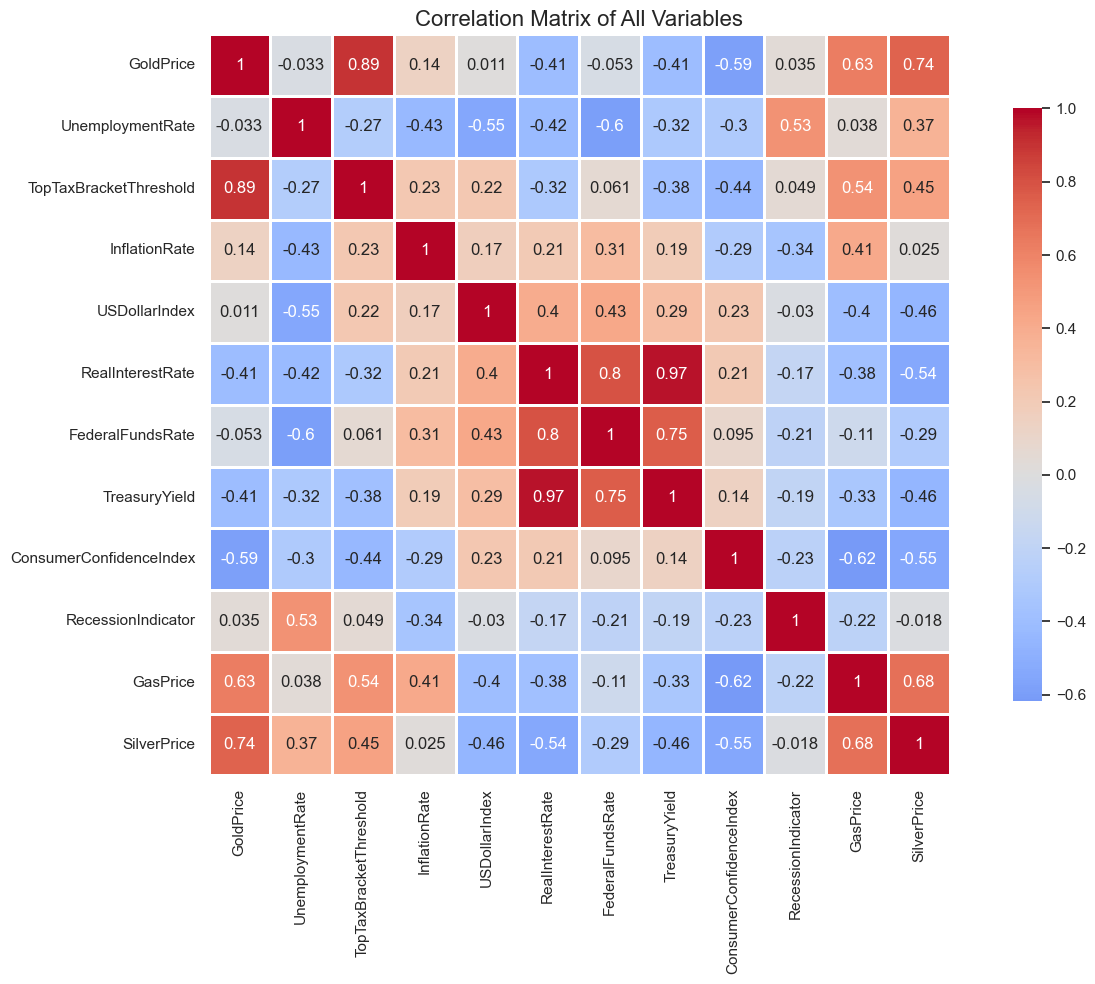

In [17]:
plt.figure(figsize=(14, 10))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix of All Variables", fontsize=16)
plt.tight_layout()
plt.show()

### Pair Plot

<Figure size 640x480 with 0 Axes>

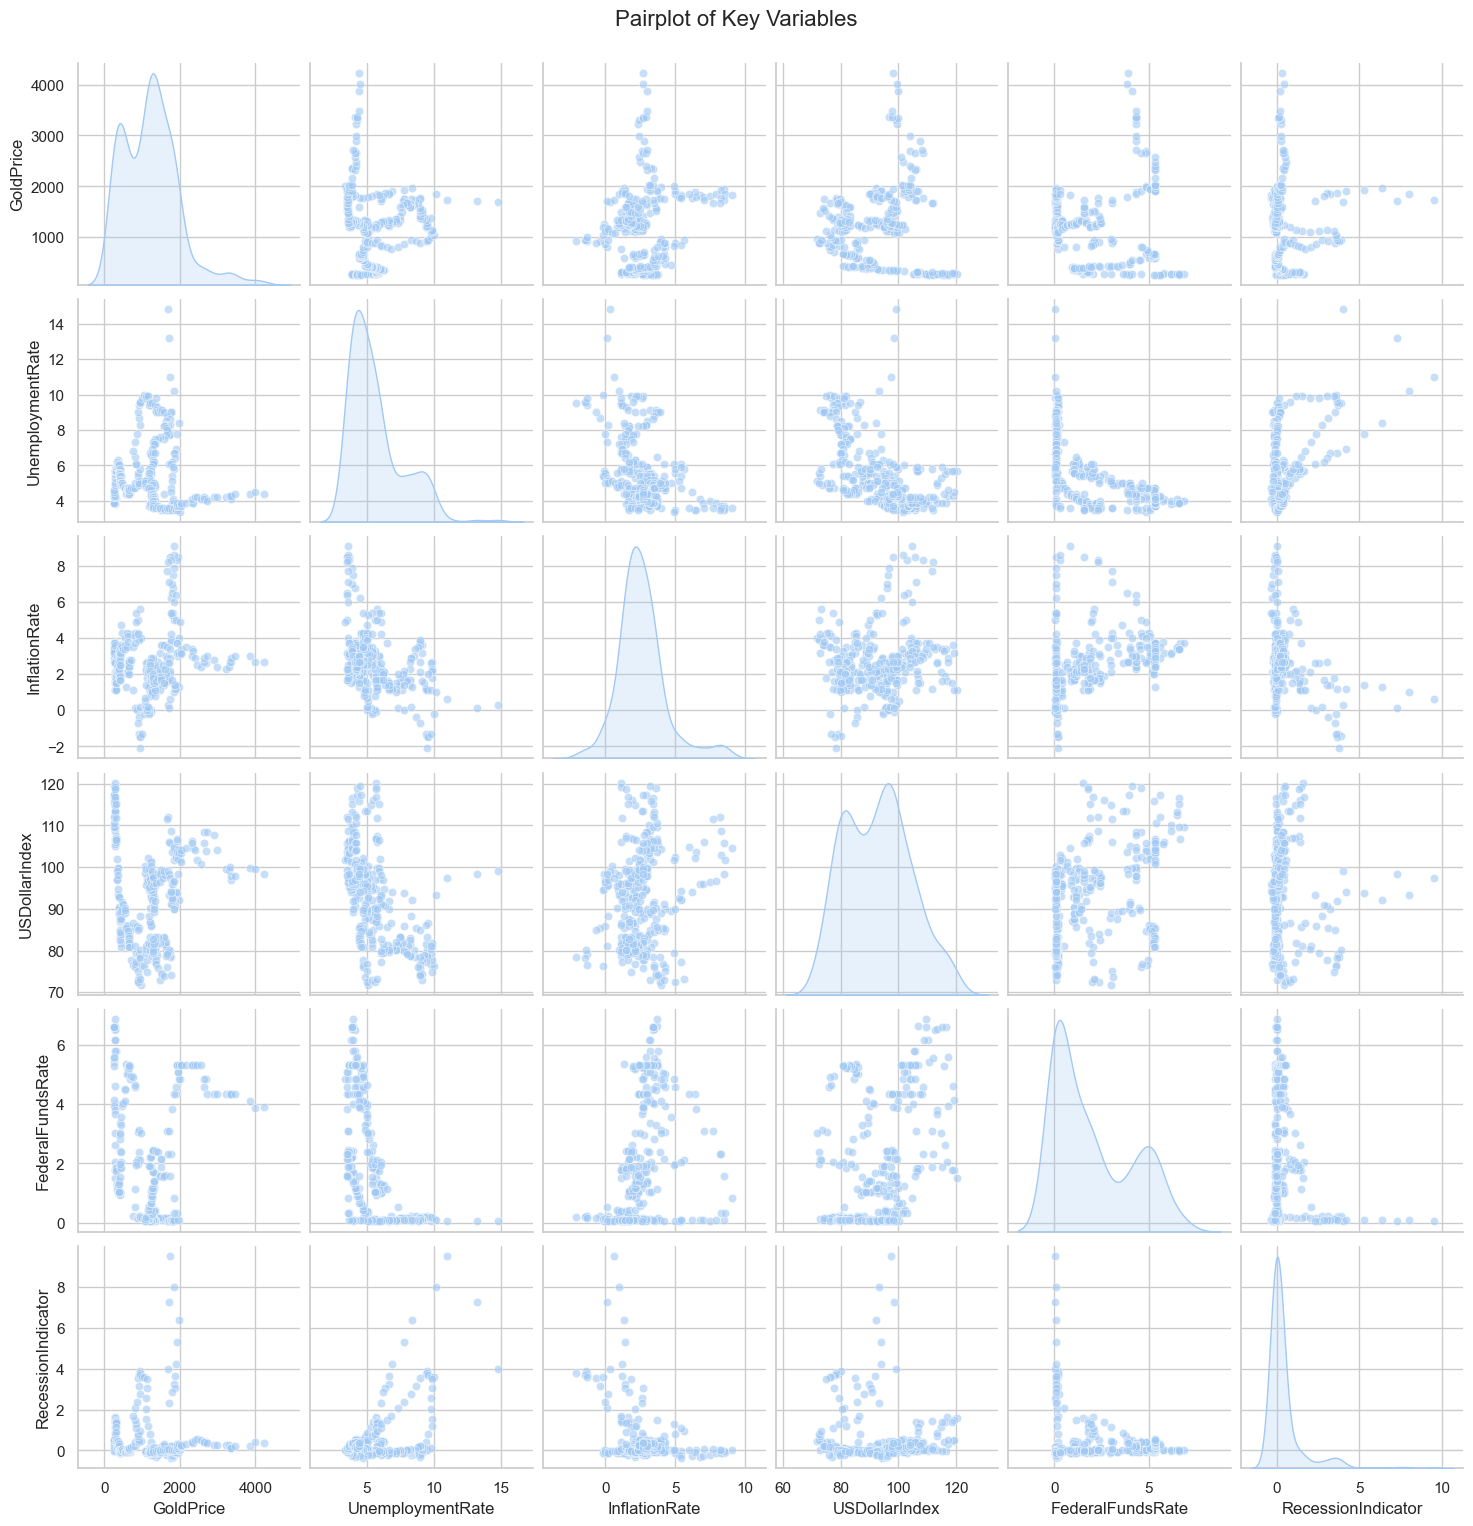

In [19]:
selected_vars = ["GoldPrice", "UnemploymentRate", "InflationRate",
                 "USDollarIndex", "FederalFundsRate", "RecessionIndicator"]

plt.figure()
sns.pairplot(df[selected_vars], diag_kind="kde", plot_kws={"alpha": 0.6})
plt.suptitle("Pairplot of Key Variables", y=1.02, fontsize=16)
plt.show()

### Safe-Heaven Behavior Analysis

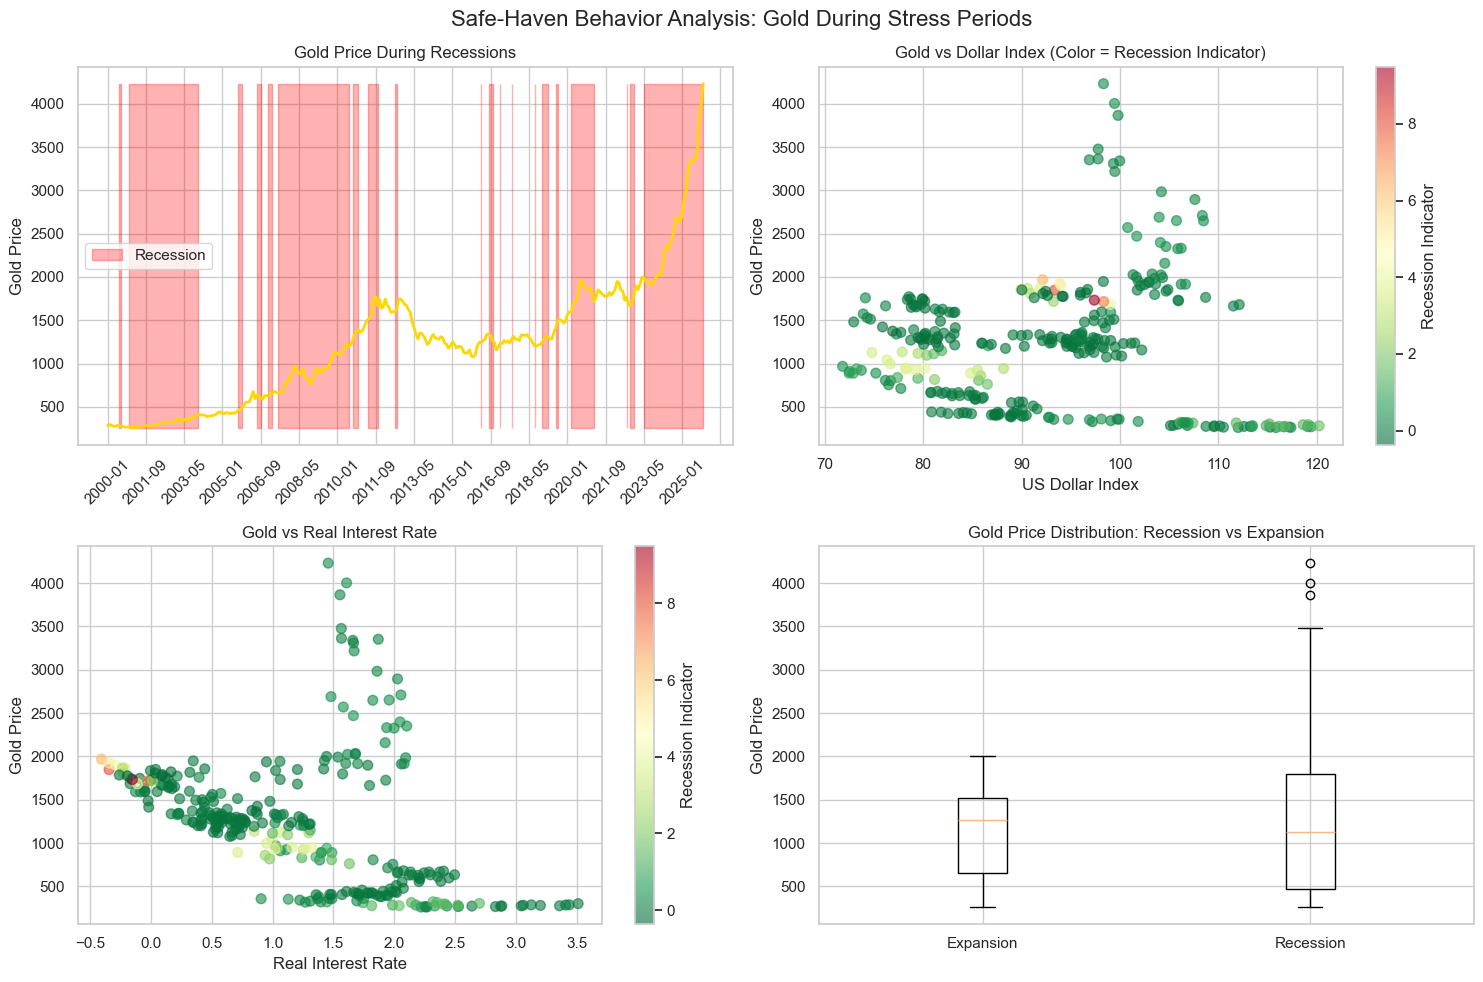

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("Safe-Haven Behavior Analysis: Gold During Stress Periods", fontsize=16)

# Gold price with recession shading
ax1 = axes[0, 0]
ax1.plot(df.index, df["GoldPrice"], color="gold", linewidth=2)
ax1.fill_between(df.index, df["GoldPrice"].min(), df["GoldPrice"].max(),
                  where=df["RecessionIndicator"] > 0, color="red", alpha=0.3, label="Recession")
ax1.set_title("Gold Price During Recessions")
ax1.set_ylabel("Gold Price")
ax1.tick_params(axis="x", rotation=45)
ax1.xaxis.set_major_locator(plt.MaxNLocator(20))
ax1.legend()

# Gold vs Dollar Index (inverse relationship for safe-haven)
ax2 = axes[0, 1]
ax2.scatter(df["USDollarIndex"], df["GoldPrice"], c=df["RecessionIndicator"],
            cmap="RdYlGn_r", alpha=0.6, s=50)
ax2.set_xlabel("US Dollar Index")
ax2.set_ylabel("Gold Price")
ax2.set_title("Gold vs Dollar Index (Color = Recession Indicator)")
cbar = plt.colorbar(ax2.collections[0], ax=ax2)
cbar.set_label("Recession Indicator")

# Gold vs Real Interest Rate
ax3 = axes[1, 0]
ax3.scatter(df["RealInterestRate"], df["GoldPrice"], c=df["RecessionIndicator"],
            cmap="RdYlGn_r", alpha=0.6, s=50)
ax3.set_xlabel("Real Interest Rate")
ax3.set_ylabel("Gold Price")
ax3.set_title("Gold vs Real Interest Rate")
cbar = plt.colorbar(ax3.collections[0], ax=ax3)
cbar.set_label("Recession Indicator")

# Gold volatility during recessions vs expansions
recession_data = df[df["RecessionIndicator"] > 0]["GoldPrice"]
expansion_data = df[df["RecessionIndicator"] <= 0]["GoldPrice"]

ax4 = axes[1, 1]
ax4.boxplot([expansion_data, recession_data], tick_labels=["Expansion", "Recession"])
ax4.set_ylabel("Gold Price")
ax4.set_title("Gold Price Distribution: Recession vs Expansion")

plt.tight_layout()
plt.show()

### Time Series Decomposition

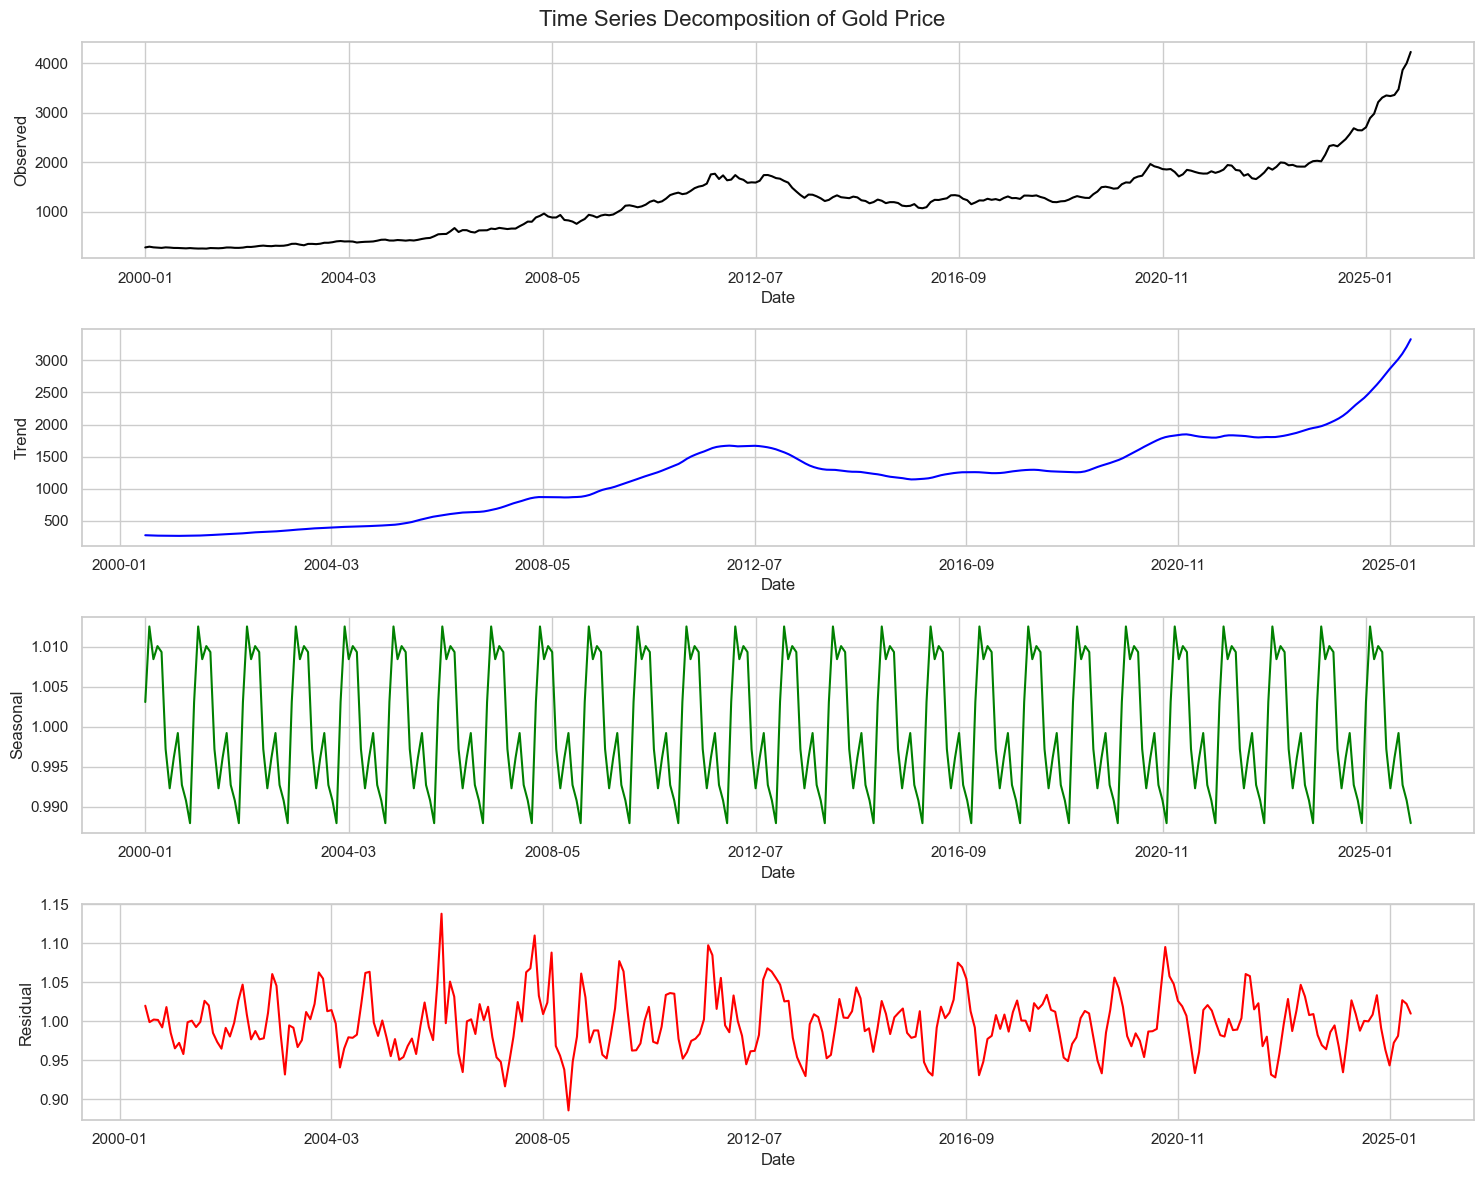

In [21]:
decomposition = seasonal_decompose(df["GoldPrice"], model="multiplicative", period=12)

fig, axes = plt.subplots(4, 1, figsize=(15, 12))
fig.suptitle("Time Series Decomposition of Gold Price", fontsize=16)

decomposition.observed.plot(ax=axes[0], color="black")
axes[0].set_ylabel("Observed")

decomposition.trend.plot(ax=axes[1], color="blue")
axes[1].set_ylabel("Trend")

decomposition.seasonal.plot(ax=axes[2], color="green")
axes[2].set_ylabel("Seasonal")

decomposition.resid.plot(ax=axes[3], color="red")
axes[3].set_ylabel("Residual")

plt.tight_layout()
plt.show()

### Lag Correlation Analysis

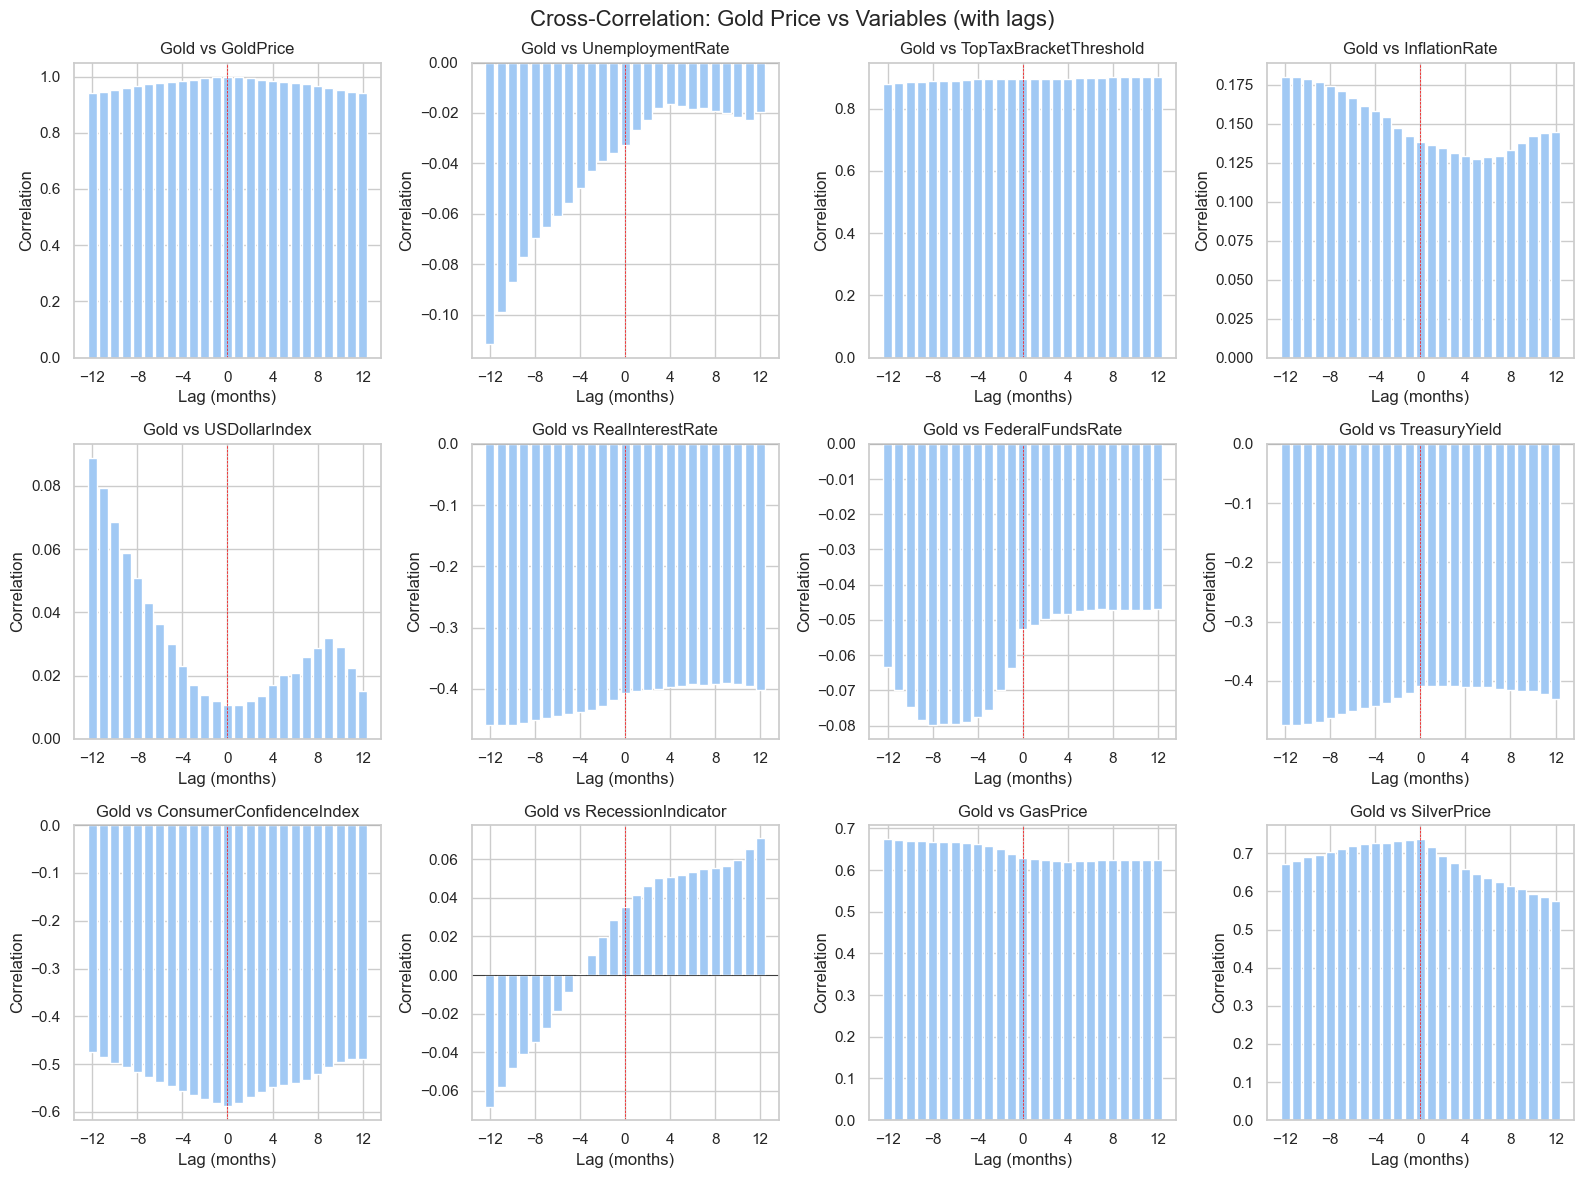

In [22]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
fig.suptitle("Cross-Correlation: Gold Price vs Variables (with lags)", fontsize=16)

for i, var in enumerate(df.columns):
    if var != "Gold Price":
        ax = axes[i // 4, i % 4]
        # Calculate correlation with lagged gold price
        lags = range(-12, 13)
        correlations = [df["GoldPrice"].corr(df[var].shift(lag)) for lag in lags]

        ax.bar(lags, correlations, width=0.8)
        ax.axhline(y=0, color="black", linestyle="-", linewidth=0.5)
        ax.axvline(x=0, color="red", linestyle="--", linewidth=0.5)
        ax.set_title(f"Gold vs {var}")
        ax.set_xlabel("Lag (months)")
        ax.set_ylabel("Correlation")
        ax.set_xticks(range(-12, 13, 4))

plt.tight_layout()
plt.show()

## Assumptions

In [23]:
gold = df["GoldPrice"].values
log_gold = np.log(gold)
gold = (gold - np.mean(gold)) / np.std(gold)
log_gold = (log_gold - np.mean(log_gold)) / np.std(log_gold)

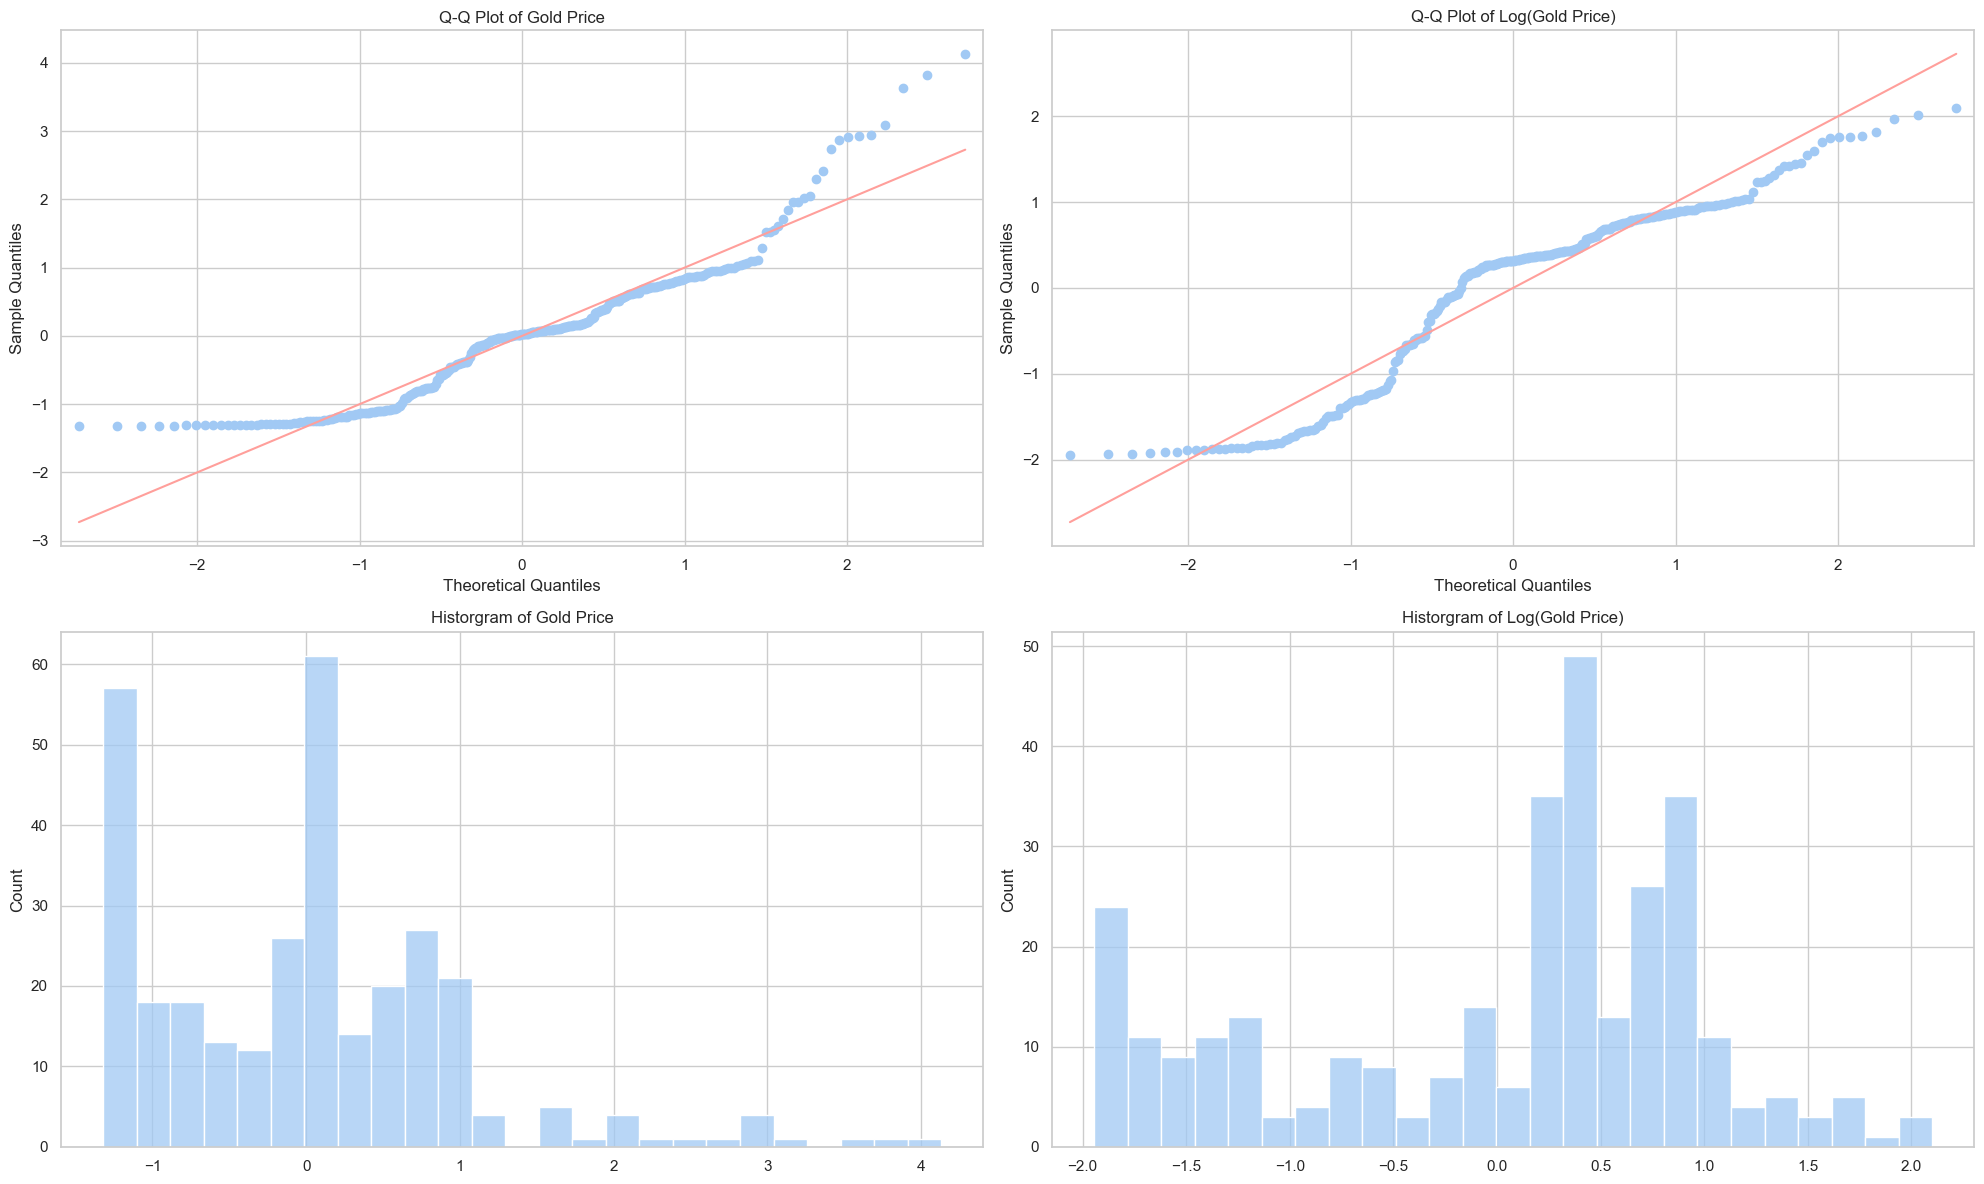

In [24]:
_, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 12))

sm.qqplot(gold, line="s", ax=axes[0, 0])
axes[0, 0].set_title("Q-Q Plot of Gold Price")
sns.histplot(gold, ax=axes[1, 0], bins=25)
axes[1, 0].set_title("Historgram of Gold Price")

sm.qqplot(log_gold, line="s", ax=axes[0, 1])
axes[0, 1].set_title("Q-Q Plot of Log(Gold Price)")
sns.histplot(log_gold, ax=axes[1, 1], bins=25)
axes[1, 1].set_title("Historgram of Log(Gold Price)")

plt.tight_layout()
plt.show()

In [25]:
default_stat = stats.shapiro(gold).statistic
log_stat = stats.shapiro(log_gold).statistic
print(f"Test statistics of Shapiro tests for differnet transformations: default {default_stat:.5f} / log {log_stat:.5f}")

Test statistics of Shapiro tests for differnet transformations: default 0.91728 / log 0.92138


## Analysis

In [26]:
df_mean = df.mean(axis=0)
df_std = df.std(axis=0)
df_norm = (df - df_mean) / df_std
df_norm.head(5)

,GoldPrice,UnemploymentRate,TopTaxBracketThreshold,InflationRate,USDollarIndex,RealInterestRate,FederalFundsRate,TreasuryYield,ConsumerConfidenceIndex,RecessionIndicator,GasPrice,SilverPrice
Date,,,,,,,,,,,,
2000-01,-1.286260,-0.844380,-1.314997,0.065467,1.079627,2.618869,0.969256,2.506151,2.163459,-0.408040,-1.772932,-1.172750
2000-02,-1.264958,-0.792905,-1.314997,0.353152,1.149037,2.739402,1.851068,2.536823,2.113153,-0.384037,-1.705028,-1.204970
2000-03,-1.283422,-0.844380,-1.314997,0.698375,1.106864,2.653389,1.846169,2.360461,1.811337,-0.384037,-1.479536,-1.238060
2000-04,-1.292606,-0.947329,-1.314997,0.295615,1.519810,2.373678,2.037228,2.061413,1.962242,-0.408040,-1.476974,-1.238931
2000-05,-1.298775,-0.844380,-1.314997,0.353152,1.396805,2.559340,2.037228,2.283782,2.070041,-0.384037,-1.583314,-1.246768


In [27]:
response = "GoldPrice"

def fit_regression(df, powers=[]):
    covariates = df.columns[df.columns != response]
    formula = f"{response} ~ {" + ".join([f"np.power({var}, 2)" if var in powers else var for var in covariates])}"

    model = smf.ols(formula, data=df).fit()
    return model

def plot_regression_line(df, models, ax=None, model_name=None):
    if ax is None:
        _, ax = plt.subplots(nrows=1, ncols=1, figsize=(12, 6))

    sns.scatterplot(x=df.index, y=df[response], color="lightblue", s=20, ax=ax)

    if not isinstance(models, list):
        models = [(models, "", "red")]

    for (model, label, color) in models:
        sns.lineplot(x=df.index, y=model.predict(df), color=color, label=label, alpha=0.4, ax=ax)

    ax.tick_params(axis="x", rotation=45)
    ax.xaxis.set_major_locator(plt.MaxNLocator(20))

    ax.set_xlabel("Date Index")
    ax.set_ylabel("Gold Price")
    ax.set_title(f"Regression line for {model_name} model")

### Analysis on Relationships between Gold Price and Economic Statistics

#### Baseline Model with all column values generated from a Normal Distribution with Mean 0 and Standard Deviation 1

Lets test by randomly generating values from a normal distribution for each column after normalizing each column and creating a model

In [28]:
df_baseline = df_norm.copy(deep=True)
rng = np.random.default_rng()
df_baseline.iloc[:, 1:] = rng.normal(loc=0.0, scale=1.0, size=(df_baseline.shape[0], df_baseline.shape[1] - 1))

In [29]:
baseline_model = fit_regression(df_baseline)
print(baseline_model.summary())

                            OLS Regression Results                            
Dep. Variable:              GoldPrice   R-squared:                       0.036
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.008
Date:                Sat, 14 Mar 2026   Prob (F-statistic):              0.439
Time:                        15:39:51   Log-Likelihood:                -436.55
No. Observations:                 312   AIC:                             897.1
Df Residuals:                     300   BIC:                             942.0
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

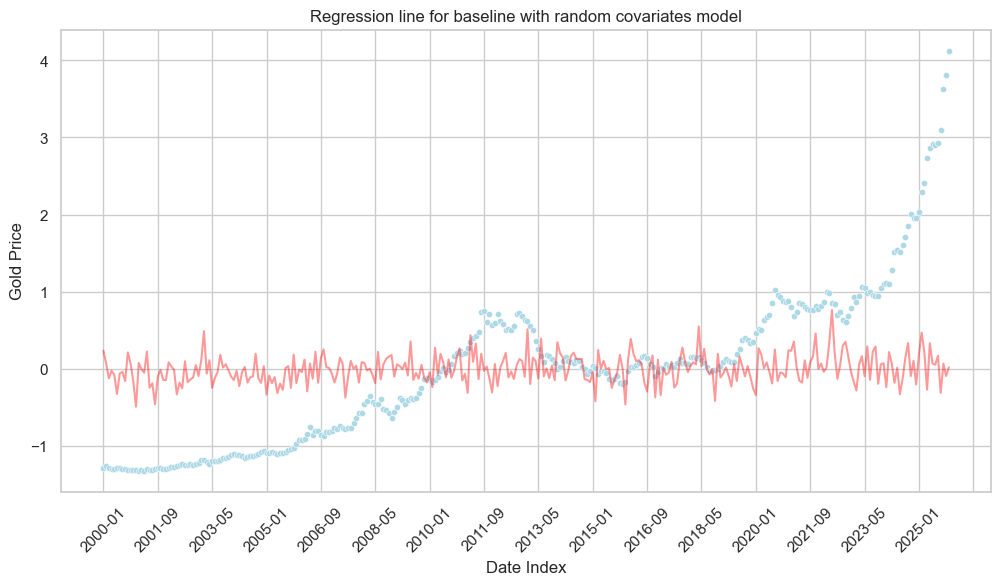

In [30]:
plot_regression_line(df_baseline, baseline_model, ax=None, model_name="baseline with random covariates")

Here we can actually notice that **ALL** of the coefficients are deemed insignificant (in the full model) because these values were generated at random. Additionally, the R-Squared being so low indicates this baseline model with randomly generated data is clearly unable to describe the data. Seen later on, strangely the condition number increases to extremely large numbers, but this could be because the data is actually correlated to the output, as well as the data in these columns being explainable and not entirely "random" as seen here

#### Full Model ( all Covariates )

In [31]:
full_model = fit_regression(df_norm)
print(full_model.summary())

                            OLS Regression Results                            
Dep. Variable:              GoldPrice   R-squared:                       0.957
Model:                            OLS   Adj. R-squared:                  0.956
Method:                 Least Squares   F-statistic:                     610.4
Date:                Sat, 14 Mar 2026   Prob (F-statistic):          4.96e-198
Time:                        15:39:51   Log-Likelihood:                 49.491
No. Observations:                 312   AIC:                            -74.98
Df Residuals:                     300   BIC:                            -30.07
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                2

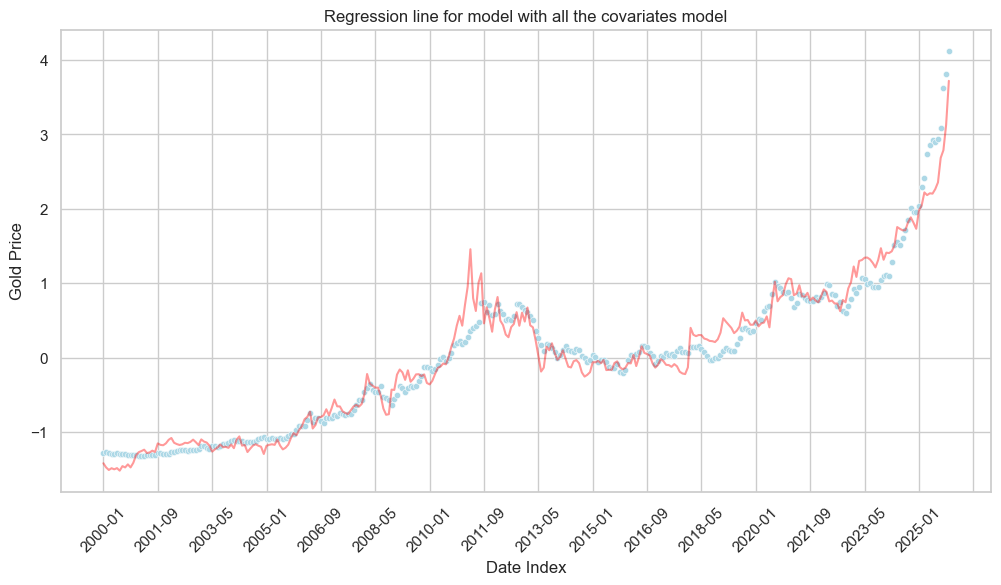

In [32]:
plot_regression_line(df_norm, full_model, ax=None, model_name="model with all the covariates")

The R-squared and Adjusted R-Squared of approx. 0.95 is a promising sign of the model fitting well with just these covariates

#### Removing Variables by using VIF from Full Model

In [33]:
def analyze_variable_VIF(model):
    exog = model.model.exog
    names = model.params.index
    for i in range(1, exog.shape[1]):
        print(f"VIF: {names[i]}: {variance_inflation_factor(exog, i): .3f}")

In [34]:
analyze_variable_VIF(full_model)

VIF: UnemploymentRate:  6.036
VIF: TopTaxBracketThreshold:  4.785
VIF: InflationRate:  2.092
VIF: USDollarIndex:  2.701
VIF: RealInterestRate:  38.208
VIF: FederalFundsRate:  5.038
VIF: TreasuryYield:  33.468
VIF: ConsumerConfidenceIndex:  3.077
VIF: RecessionIndicator:  2.963
VIF: GasPrice:  4.816
VIF: SilverPrice:  3.650


From the broad observations about each coefficient"s p-value, `index`, `UnemploymentRate`, `RealInterestRate`, `FederalFundsRate`, and `TreasuryYield` indeed have the top VIFs. What happens as we drop the covariates with the highest VIFs above 5 (from greatest to least)

In [35]:
df_vif1 = df_norm.drop(columns = ["RealInterestRate"])
vif_model1 = fit_regression(df_vif1)
print(vif_model1.summary())

                            OLS Regression Results                            
Dep. Variable:              GoldPrice   R-squared:                       0.957
Model:                            OLS   Adj. R-squared:                  0.956
Method:                 Least Squares   F-statistic:                     670.0
Date:                Sat, 14 Mar 2026   Prob (F-statistic):          4.07e-199
Time:                        15:39:52   Log-Likelihood:                 48.678
No. Observations:                 312   AIC:                            -75.36
Df Residuals:                     301   BIC:                            -34.18
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                2

In [36]:
analyze_variable_VIF(vif_model1)

VIF: UnemploymentRate:  5.820
VIF: TopTaxBracketThreshold:  4.760
VIF: InflationRate:  2.078
VIF: USDollarIndex:  2.677
VIF: FederalFundsRate:  4.807
VIF: TreasuryYield:  5.034
VIF: ConsumerConfidenceIndex:  3.005
VIF: RecessionIndicator:  2.804
VIF: GasPrice:  4.807
VIF: SilverPrice:  3.518


In [37]:
df_vif2= df_norm.drop(columns = ["RealInterestRate", "UnemploymentRate"])
vif_model2 = fit_regression(df_vif2)
print(vif_model2.summary())

                            OLS Regression Results                            
Dep. Variable:              GoldPrice   R-squared:                       0.957
Model:                            OLS   Adj. R-squared:                  0.956
Method:                 Least Squares   F-statistic:                     745.5
Date:                Sat, 14 Mar 2026   Prob (F-statistic):          1.89e-200
Time:                        15:39:52   Log-Likelihood:                 48.400
No. Observations:                 312   AIC:                            -76.80
Df Residuals:                     302   BIC:                            -39.37
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                2

In [38]:
analyze_variable_VIF(vif_model2)

VIF: TopTaxBracketThreshold:  3.623
VIF: InflationRate:  1.894
VIF: USDollarIndex:  2.660
VIF: FederalFundsRate:  3.946
VIF: TreasuryYield:  4.904
VIF: ConsumerConfidenceIndex:  2.809
VIF: RecessionIndicator:  1.770
VIF: GasPrice:  4.784
VIF: SilverPrice:  2.736


In [39]:
df_vif3 = df_norm.drop(columns = ["RealInterestRate", "UnemploymentRate", "TreasuryYield", "FederalFundsRate"])
vif_model3 = fit_regression(df_vif3)
print(vif_model3.summary())

                            OLS Regression Results                            
Dep. Variable:              GoldPrice   R-squared:                       0.956
Model:                            OLS   Adj. R-squared:                  0.955
Method:                 Least Squares   F-statistic:                     946.3
Date:                Sat, 14 Mar 2026   Prob (F-statistic):          3.30e-202
Time:                        15:39:52   Log-Likelihood:                 45.503
No. Observations:                 312   AIC:                            -75.01
Df Residuals:                     304   BIC:                            -45.06
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                2

In [40]:
analyze_variable_VIF(vif_model3)

VIF: TopTaxBracketThreshold:  2.638
VIF: InflationRate:  1.833
VIF: USDollarIndex:  2.539
VIF: ConsumerConfidenceIndex:  2.358
VIF: RecessionIndicator:  1.655
VIF: GasPrice:  4.702
VIF: SilverPrice:  2.639


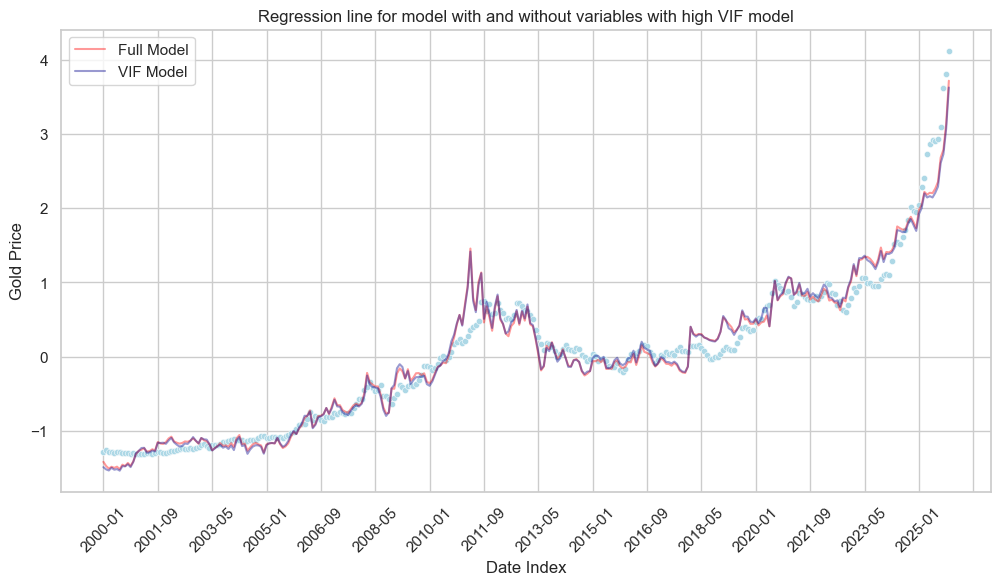

In [41]:
models = [
    (full_model, "Full Model", "red"),
    (vif_model3, "VIF Model", "darkblue")]

plot_regression_line(df_norm, models, ax=None, model_name="model with and without variables with high VIF")

While difficult to visually observe, it appears that after filtering (red), the prediction plot does have basically the same structure, which can also be observed in the summary"s barely different R-squared(s). Visually, it appears the filtered covariates have some reduced peaks and valleys compared to the prior model.

### Backwards Selection for Variables based on BIC metric

In [42]:
def criterion_bic(formula, df):

    model = smf.ols(formula, df).fit()
    criterion_value = model.bic
    return criterion_value

def criterion_aic(formula, df):

    model = smf.ols(formula, df).fit()
    criterion_value = model.aic
    return criterion_value

def remove(df, already_selected_columns, criterion, response="y"):

    # initialize the worst criterion and column to None
    worst_criterion = criterion(f"{response} ~ {" + ".join(already_selected_columns)}", df)
    worst_column = None

    # iterate over the already selected columns to find the worst column to remove
    for column in already_selected_columns:
        # print(column, already_selected_columns)

        new_columns = {x for x in already_selected_columns if x != column}
        # print(new_columns)

        formula = f"{response} ~ {" + ".join(new_columns)}"
        current_criterion = criterion(formula, df)

        if current_criterion < worst_criterion:
            worst_criterion = current_criterion
            worst_column = column
    return worst_column, worst_criterion

def backward(df, criterion, response="y"):

    print("Start backward selection:")
    # initialize the set of already selected columns to all columns except the response variable
    already_selected_columns = set(df.columns.drop(response))
    # print(already_selected_columns)
    # print(f"{response} ~ {" + ".join(already_selected_columns)}")

    best_criterion = criterion(f"{response} ~ {" + ".join(already_selected_columns)}", df)
    while len(already_selected_columns) > 0:

        # identify the worst column to remove based on the given criterion
        potential_column, current_criterion = remove(df, already_selected_columns, criterion, response)

        # check if the model with the worst column removed has a better criterion value
        if current_criterion < best_criterion:

            already_selected_columns =  {x for x in already_selected_columns if x != potential_column}
            best_criterion = current_criterion
            print(f"  Criterion: {best_criterion}")
        else:

            break

    final_selection = already_selected_columns
    return final_selection

In [43]:
backward_bic_vars = backward(df_norm, criterion_bic, response)
print(f"Final selected variables with BIC: \n  {", ".join(backward_bic_vars)}")

Start backward selection:
  Criterion: -35.37456938868022
  Criterion: -40.49508634507278
  Criterion: -44.621166332636264
  Criterion: -45.061748574356635
Final selected variables with BIC: 
  GasPrice, ConsumerConfidenceIndex, SilverPrice, USDollarIndex, RecessionIndicator, InflationRate, TopTaxBracketThreshold


In [44]:
df_backward_bic = df_norm[[response] + list(backward_bic_vars)]
backward_bic_model = fit_regression(df_backward_bic)
print(backward_bic_model.summary())

                            OLS Regression Results                            
Dep. Variable:              GoldPrice   R-squared:                       0.956
Model:                            OLS   Adj. R-squared:                  0.955
Method:                 Least Squares   F-statistic:                     946.3
Date:                Sat, 14 Mar 2026   Prob (F-statistic):          3.30e-202
Time:                        15:39:52   Log-Likelihood:                 45.503
No. Observations:                 312   AIC:                            -75.01
Df Residuals:                     304   BIC:                            -45.06
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                2

In [45]:
print(f"Variables chosen by VIF factor filtering:\n  {", ".join(sorted(df_vif3.columns[1:]))}")
print(f"Variables chosen by backward selection:\n  {", ".join(sorted(df_backward_bic.columns[1:]))}")

Variables chosen by VIF factor filtering:
  ConsumerConfidenceIndex, GasPrice, InflationRate, RecessionIndicator, SilverPrice, TopTaxBracketThreshold, USDollarIndex
Variables chosen by backward selection:
  ConsumerConfidenceIndex, GasPrice, InflationRate, RecessionIndicator, SilverPrice, TopTaxBracketThreshold, USDollarIndex


Using backwards selection using BIC as the metric, we arrive at the same formula for the covariates after manual filtering.

In [46]:
backward_aic_vars = backward(df_norm, criterion_aic, response)
print(f"Final selected variables with BIC: \n  {", ".join(backward_aic_vars)}")

Start backward selection:
  Criterion: -76.54760445458453
  Criterion: -77.9251182231676
  Criterion: -78.30819502292161
Final selected variables with BIC: 
  GasPrice, TreasuryYield, ConsumerConfidenceIndex, SilverPrice, USDollarIndex, RecessionIndicator, InflationRate, TopTaxBracketThreshold


Using AIC as the criterion actually arrives at a more complex model

In [47]:
df_backward_aic = df_norm[[response] + list(backward_aic_vars)]
backward_aic_model = fit_regression(df_backward_aic)
print(backward_aic_model.summary())

                            OLS Regression Results                            
Dep. Variable:              GoldPrice   R-squared:                       0.957
Model:                            OLS   Adj. R-squared:                  0.956
Method:                 Least Squares   F-statistic:                     840.1
Date:                Sat, 14 Mar 2026   Prob (F-statistic):          8.03e-202
Time:                        15:39:53   Log-Likelihood:                 48.154
No. Observations:                 312   AIC:                            -78.31
Df Residuals:                     303   BIC:                            -44.62
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                2

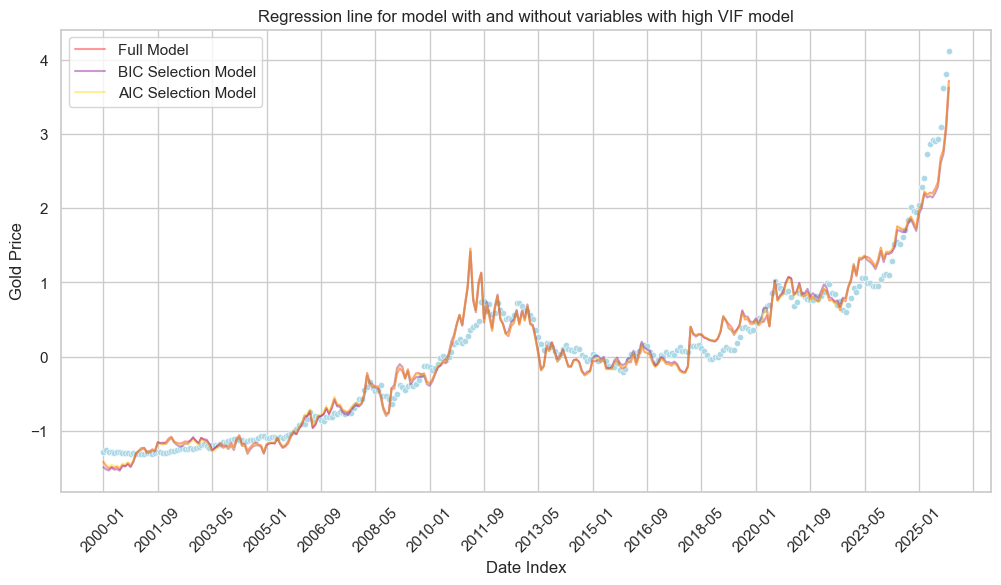

In [48]:
models = [
    (full_model, "Full Model", "red"),
    (backward_bic_model, "BIC Selection Model", "purple"),
    (backward_aic_model, "AIC Selection Model", "gold")
]

plot_regression_line(df_norm, models, ax=None, model_name="model with and without variables with high VIF")

As seen above, the models produced by these different covariate selection - methods barely differ visually and numerically in the OLS summaries.

In [49]:
print("Adjusted R-squared Metric for each model")
print(f"  Full Model: {full_model.rsquared_adj}")
print(f"  VIF filtered Model: {vif_model3.rsquared_adj}")
print(f"  BIC Backwards Selection Model: {backward_bic_model.rsquared_adj}")
print(f"  AIC Backwards Selection Model: {backward_aic_model.rsquared_adj}")

Adjusted R-squared Metric for each model
  Full Model: 0.9556616925691863
  VIF filtered Model: 0.9551120885547705
  BIC Backwards Selection Model: 0.9551120885547705
  AIC Backwards Selection Model: 0.9557228615122991


Here we can see the AIC selected model actually has the best Adjusted R-squared of these couple methods of arriving at an "optimal" formula

### Applying Log Transform to Gold Price

In [50]:
df_log = df.copy(deep=True)
df_log[response] = np.log(df_log[response])

df_log_mean = df_log.mean(axis=0)
df_log_std = df_log.std(axis=0)
df_log = (df_log - df_log_mean) / df_log_std
df_log.head(5)

,GoldPrice,UnemploymentRate,TopTaxBracketThreshold,InflationRate,USDollarIndex,RealInterestRate,FederalFundsRate,TreasuryYield,ConsumerConfidenceIndex,RecessionIndicator,GasPrice,SilverPrice
Date,,,,,,,,,,,,
2000-01,-1.814694,-0.844380,-1.314997,0.065467,1.079627,2.618869,0.969256,2.506151,2.163459,-0.408040,-1.772932,-1.172750
2000-02,-1.737597,-0.792905,-1.314997,0.353152,1.149037,2.739402,1.851068,2.536823,2.113153,-0.384037,-1.705028,-1.204970
2000-03,-1.804184,-0.844380,-1.314997,0.698375,1.106864,2.653389,1.846169,2.360461,1.811337,-0.384037,-1.479536,-1.238060
2000-04,-1.838480,-0.947329,-1.314997,0.295615,1.519810,2.373678,2.037228,2.061413,1.962242,-0.408040,-1.476974,-1.238931
2000-05,-1.861979,-0.844380,-1.314997,0.353152,1.396805,2.559340,2.037228,2.283782,2.070041,-0.384037,-1.583314,-1.246768


In [51]:
log_model = fit_regression(df_log)
print(log_model.summary())

                            OLS Regression Results                            
Dep. Variable:              GoldPrice   R-squared:                       0.980
Model:                            OLS   Adj. R-squared:                  0.979
Method:                 Least Squares   F-statistic:                     1318.
Date:                Sat, 14 Mar 2026   Prob (F-statistic):          1.28e-246
Time:                        15:39:53   Log-Likelihood:                 165.95
No. Observations:                 312   AIC:                            -307.9
Df Residuals:                     300   BIC:                            -263.0
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept               -1

In [52]:
analyze_variable_VIF(log_model)

VIF: UnemploymentRate:  6.036
VIF: TopTaxBracketThreshold:  4.785
VIF: InflationRate:  2.092
VIF: USDollarIndex:  2.701
VIF: RealInterestRate:  38.208
VIF: FederalFundsRate:  5.038
VIF: TreasuryYield:  33.468
VIF: ConsumerConfidenceIndex:  3.077
VIF: RecessionIndicator:  2.963
VIF: GasPrice:  4.816
VIF: SilverPrice:  3.650


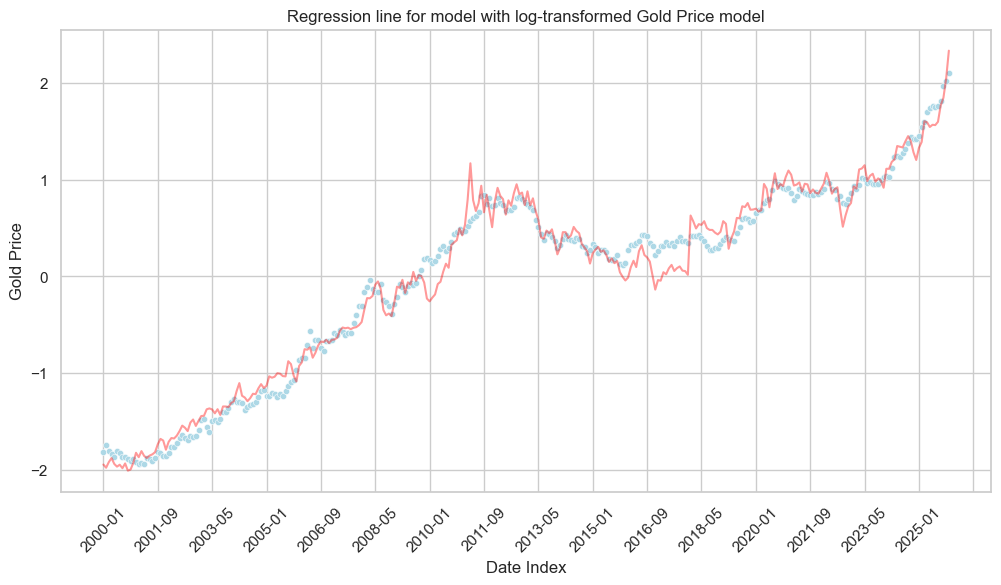

In [53]:
plot_regression_line(df_log, log_model, ax=None, model_name="model with log-transformed Gold Price")

In [54]:
log_backward_bic_vars = backward(df_log, criterion_bic, response)
print(f"Final selected variables with log-transformation and BIC: \n  {", ".join(log_backward_bic_vars)}")

Start backward selection:
  Criterion: -266.5489210602227
  Criterion: -267.14949407677943
Final selected variables with log-transformation and BIC: 
  GasPrice, RealInterestRate, TreasuryYield, ConsumerConfidenceIndex, SilverPrice, USDollarIndex, RecessionIndicator, InflationRate, TopTaxBracketThreshold


In [55]:
df_log_backward_bic = df_log[[response] + list(log_backward_bic_vars)]
backward_bic_model = fit_regression(df_log_backward_bic)
print(backward_bic_model.summary())

                            OLS Regression Results                            
Dep. Variable:              GoldPrice   R-squared:                       0.979
Model:                            OLS   Adj. R-squared:                  0.979
Method:                 Least Squares   F-statistic:                     1583.
Date:                Sat, 14 Mar 2026   Prob (F-statistic):          2.73e-248
Time:                        15:39:54   Log-Likelihood:                 162.29
No. Observations:                 312   AIC:                            -304.6
Df Residuals:                     302   BIC:                            -267.1
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept               -1

In [56]:
log_backward_aic_vars = backward(df_log, criterion_aic, response)
print(f"Final selected variables with log-transformation and BIC: \n  {", ".join(log_backward_aic_vars)}")

Start backward selection:
Final selected variables with log-transformation and BIC: 
  UnemploymentRate, GasPrice, RealInterestRate, FederalFundsRate, TreasuryYield, ConsumerConfidenceIndex, SilverPrice, USDollarIndex, RecessionIndicator, InflationRate, TopTaxBracketThreshold


In [57]:
df_log_backward_aic = df_log[[response] + list(log_backward_aic_vars)]
backward_aic_model = fit_regression(df_log_backward_aic)
print(backward_aic_model.summary())

                            OLS Regression Results                            
Dep. Variable:              GoldPrice   R-squared:                       0.980
Model:                            OLS   Adj. R-squared:                  0.979
Method:                 Least Squares   F-statistic:                     1318.
Date:                Sat, 14 Mar 2026   Prob (F-statistic):          1.28e-246
Time:                        15:39:54   Log-Likelihood:                 165.95
No. Observations:                 312   AIC:                            -307.9
Df Residuals:                     300   BIC:                            -263.0
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept               -1

Multicollinearity still high, but all variables significant now. Condition number is concerningly high but greatly reduced. Prob Omnibus and Prob JB are still 0, likely because the data observed does not follow assumptions

### Exploring Polynomials with Covariates

For this part, individual covariates in the formula will be squared and in each model, the BIC will be returned and compared to identify which, if any, yield a better (lower) BIC and thus a better fitting model. This will be done on the original dataset after standardizing all the columns ( for general interpretability of the coefficients) and log transforming the Gold Price values, including index as a measurement for time (Date). I recognize applying the log transformation adds a layer of complexity to the interpretability of the coefficients, but it does appear to yield a model that can explain the variance of data - better. However, the covariates will be limited to those chosen by the backwards selection model that used BIC as the criterion on the log transformed dataset.

In [58]:
poly_df = df_log_backward_aic.copy(deep=True)
poly_vars = poly_df.columns[1:]

In [59]:
model = fit_regression(poly_df, powers=[])

results = [["Baseline", -model.bic, model.rsquared]]
for variable in poly_vars:
    model = fit_regression(poly_df, powers=[variable])
    bic = model.bic
    rsquared = model.rsquared
    results.append([variable, -bic, rsquared])

results = pd.DataFrame(results, columns=["Squared Variable", "Negative BIC", "R-squared"])
results

,Squared Variable,Negative BIC,R-squared
0,Baseline,262.985277,0.979727
1,UnemploymentRate,265.245864,0.979873
2,GasPrice,176.246063,0.973229
3,RealInterestRate,227.337794,0.977273
4,FederalFundsRate,265.545233,0.979892
5,TreasuryYield,196.079032,0.974878
6,ConsumerConfidenceIndex,259.506234,0.979499
7,SilverPrice,88.968082,0.964588
8,USDollarIndex,244.158830,0.978466
9,RecessionIndicator,258.322974,0.979422


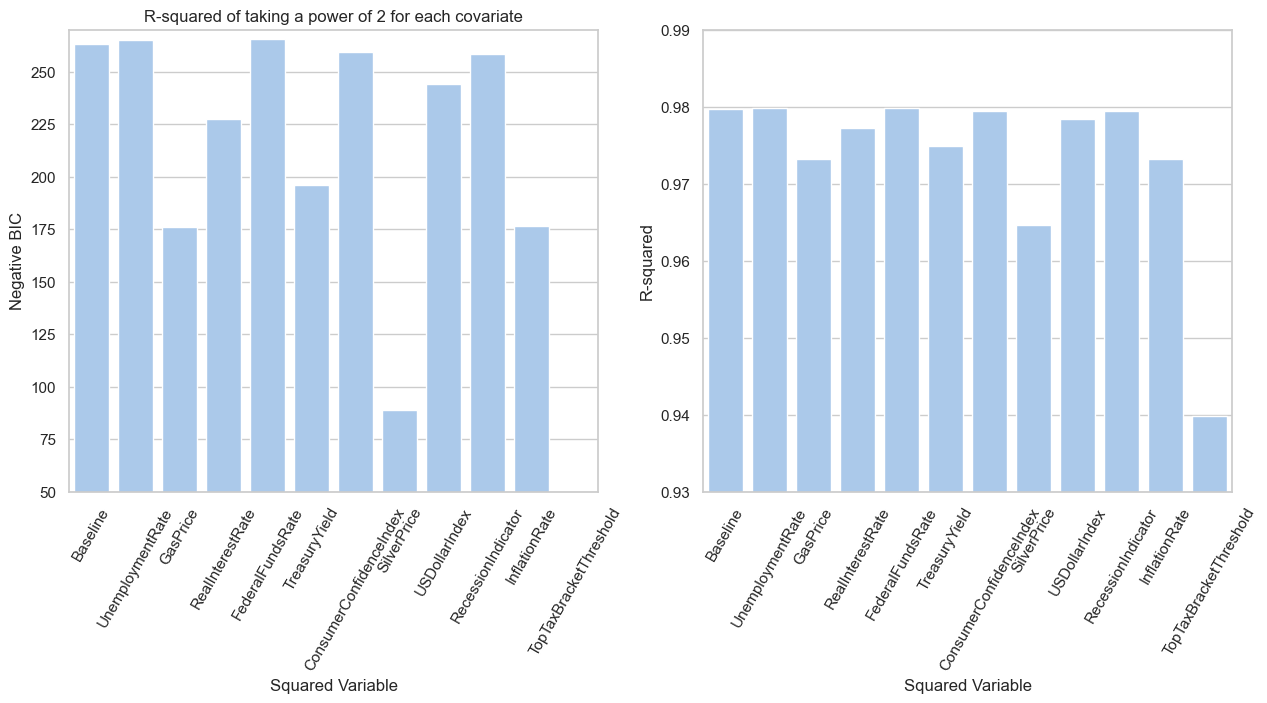

In [60]:
_, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

sns.barplot(results, x="Squared Variable", y="Negative BIC", ax=axes[0])
axes[0].set_title("Negative BIC of taking a power of 2 for each covariate")
axes[0].tick_params(axis="x", rotation=60)
axes[0].set_ylim(50, 270)

sns.barplot(results, x="Squared Variable", y="R-squared", ax=axes[1])
axes[0].set_title("R-squared of taking a power of 2 for each covariate")
axes[1].tick_params(axis="x", rotation=60)
axes[1].set_ylim(0.93, 0.99)

plt.show()

In [61]:
for metric in ["Negative BIC", "R-squared"]:
    print(f"Models with better {metric} than baseline")
    baseline =  results[metric][results["Squared Variable"] == "Baseline"].values[0]
    print(f"  Baseline: {baseline:.5f}")

    better = results[["Squared Variable", metric]][results[metric] > baseline]
    for (var, value) in better.values:
        print(f"  {var}: {value:.5f}")

Models with better Negative BIC than baseline
  Baseline: 262.98528
  UnemploymentRate: 265.24586
  FederalFundsRate: 265.54523
Models with better R-squared than baseline
  Baseline: 0.97973
  UnemploymentRate: 0.97987
  FederalFundsRate: 0.97989


In [62]:
poly_final_model = fit_regression(poly_df, powers=["FederalFundsRate"])
print(f"Negative BIC: {-poly_final_model.bic} / R-squared: {poly_final_model.rsquared}")

Negative BIC: 265.545232761024 / R-squared: 0.9798924124285384


To be interpreted simply, when transitioning from **Linear Regression** to **Polynomial (or Quadratic) Regression** by a single  covariate, the best parameter to square is `Real Interest Rate`. Additionally, this is in terms of Gold Price being log transformed, which means the whole formula becomes an exponential function (e raised to the formula as a power). However, this exploration just looks at the first covariate that can be turned into polynomial, any further impacts from raising other covariates to powers cannot be determined without testing. That said, the Linear Regression Model is quite sturdy enough to fit to the data with a high Adjusted R-Squared value, which should be ample evidence to determine there is enough information in the provided dataset to capture a (not necessarily perfect) relationship between the variables and gold prices

## Analysis on Residuals of Regression Line

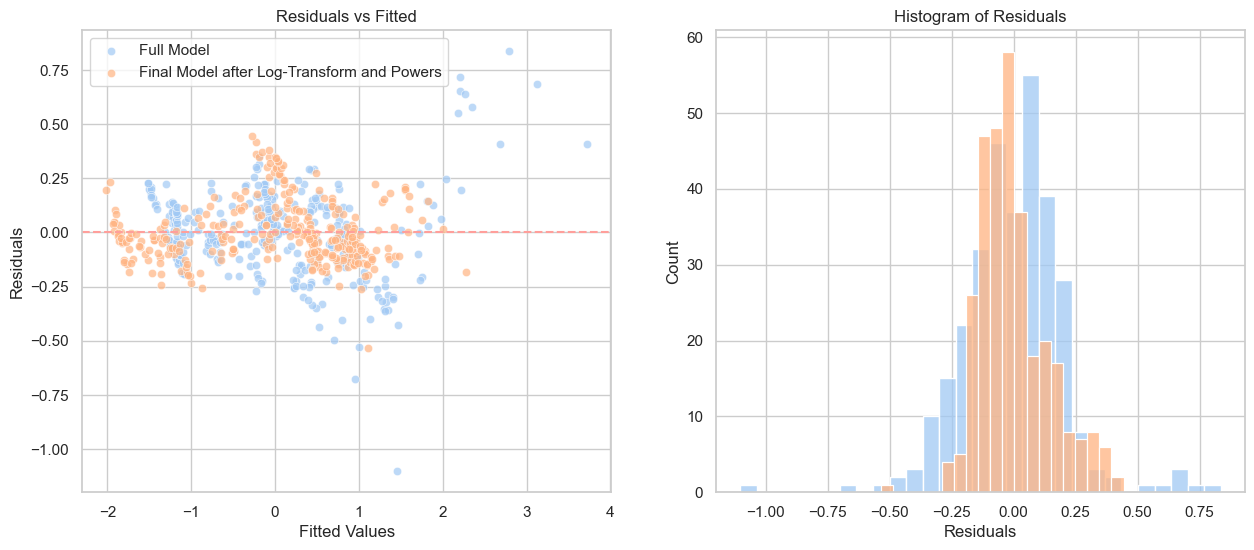

In [63]:
_, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

models = [(full_model, "Full Model"), (poly_final_model, "Final Model after Log-Transform and Powers")]
for model, model_name in models:
    residuals = model.resid
    fitted = model.fittedvalues

    sns.scatterplot(x=fitted, y=residuals, alpha=0.7, label=model_name, ax=axes[0])
    sns.histplot(x=residuals, label=model_name, ax=axes[1])

axes[0].axhline(y=0, color="r", linestyle="--")
axes[0].set_xlabel("Fitted Values")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Fitted")

axes[1].set_xlabel("Residuals")
axes[1].set_title("Histogram of Residuals")

plt.show()

In [64]:
print("Test statistics of Shapiro tests")
for model, model_name in models:
    residuals = model.resid
    result = stats.shapiro(residuals)
    print(f"  {model_name}: statistic: {result.statistic} / p-value: {result.pvalue}")

Test statistics of Shapiro tests
  Full Model: statistic: 0.9493539263517482 / p-value: 6.902578523302667e-09
  Final Model after Log-Transform and Powers: statistic: 0.9500776442527914 / p-value: 8.407252454561172e-09


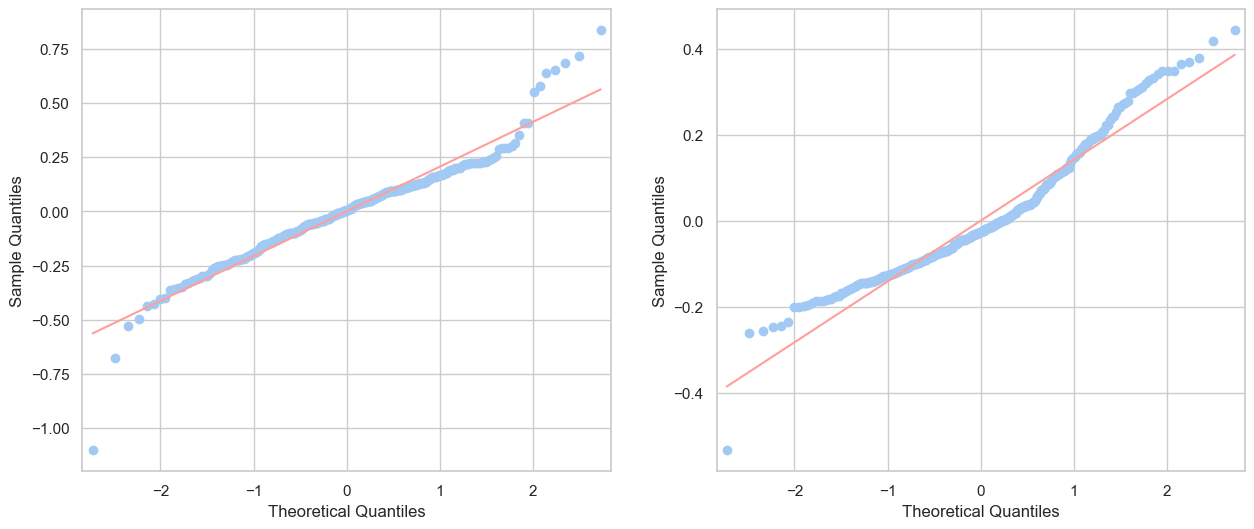

In [65]:
_, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

for i, (model, model_name) in enumerate(models):
    residuals = model.resid

    sm.qqplot(residuals, line="s", ax=axes[i])
    ax.set_title(f"Q-Q plot of residuals of {model_name}")

plt.show()

### Analysis on Time Windows
In this part, we analyze the temporal relationship between gold prices and the covariates by changing corresponding time windows. For $i \in \{0, 1, \ldots, 311\}$, let $x_i \in \mathbb{R}^{11}$ be a feature vector at index $i$ and $y_i \in \mathbb{R}$ be a gold price at index $i$.

Then in our baseline model, we tried to approximate the function $f_\text{base}: \mathbb{R}^{11} \to \mathbb{R}$ such that:

$$
y_i = f_\text{base}(x_i) \quad \text{where} \quad i \in \{0, 1, \ldots, 311\}
$$

In [66]:
def slide_time_window(df, k):
    index = df.index[k:]
    y = df.iloc[k:, 0].reset_index(drop=True)
    x = df.iloc[:-k, 1:].reset_index(drop=True)
    df_k = pd.concat([y, x], axis=1)
    df_k.index = index
    return df_k

In [67]:
df_k = slide_time_window(df_norm, 3)
df_k.head(5)

,GoldPrice,UnemploymentRate,TopTaxBracketThreshold,InflationRate,USDollarIndex,RealInterestRate,FederalFundsRate,TreasuryYield,ConsumerConfidenceIndex,RecessionIndicator,GasPrice,SilverPrice
Date,,,,,,,,,,,,
2000-04,-1.292606,-0.844380,-1.314997,0.065467,1.079627,2.618869,0.969256,2.506151,2.163459,-0.408040,-1.772932,-1.172750
2000-05,-1.298775,-0.792905,-1.314997,0.353152,1.149037,2.739402,1.851068,2.536823,2.113153,-0.384037,-1.705028,-1.204970
2000-06,-1.284327,-0.844380,-1.314997,0.698375,1.106864,2.653389,1.846169,2.360461,1.811337,-0.384037,-1.479536,-1.238060
2000-07,-1.290002,-0.947329,-1.314997,0.295615,1.519810,2.373678,2.037228,2.061413,1.962242,-0.408040,-1.476974,-1.238931
2000-08,-1.299762,-0.844380,-1.314997,0.353152,1.396805,2.559340,2.037228,2.283782,2.070041,-0.384037,-1.583314,-1.246768


In [68]:
model_k = fit_regression(df_k)
print(model_k.summary())

                            OLS Regression Results                            
Dep. Variable:              GoldPrice   R-squared:                       0.941
Model:                            OLS   Adj. R-squared:                  0.939
Method:                 Least Squares   F-statistic:                     434.4
Date:                Sat, 14 Mar 2026   Prob (F-statistic):          8.25e-176
Time:                        15:39:55   Log-Likelihood:                 1.5624
No. Observations:                 309   AIC:                             20.88
Df Residuals:                     297   BIC:                             65.68
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

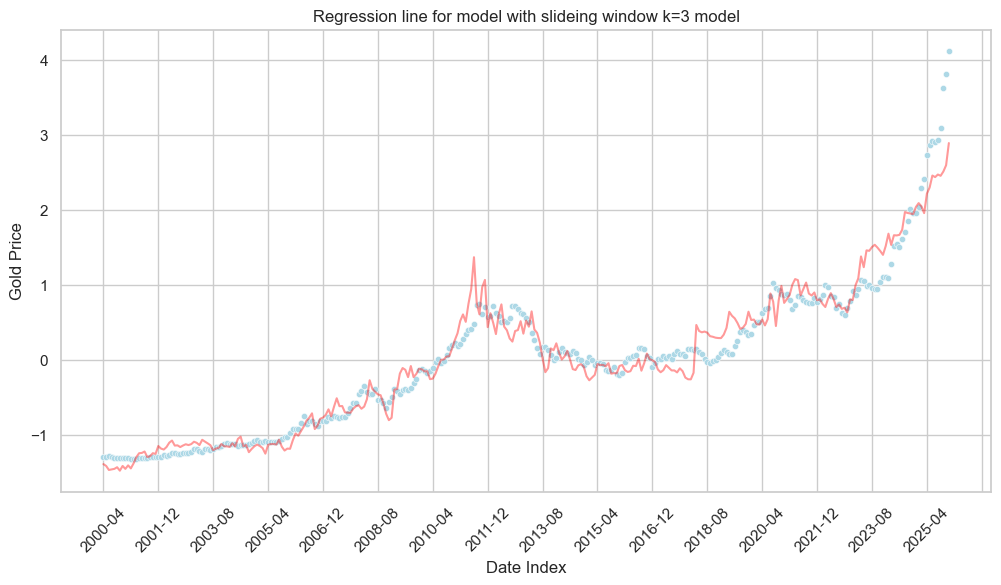

In [69]:
plot_regression_line(df_k, model_k, model_name="model with slideing window k=3")

In [70]:
results = []
for k in range(36):
    if k == 0:
        df_k = df_norm
    else:
        df_k = slide_time_window(df_norm, k)

    model_k = fit_regression(df_k)

    results.append([k, model_k.rsquared, model_k.fvalue, model_k.mse_resid, model_k.bic, ])

results = pd.DataFrame(results, columns=["k", "R Squared", "F Statistic", "MSE", "BIC"])
results.head(5)

,k,R Squared,F Statistic,MSE,BIC
0,0,0.957230,610.386419,0.044338,-30.065929
1,1,0.953131,552.775873,0.048489,-1.993477
2,2,0.945423,469.284549,0.056358,44.775124
3,3,0.941481,434.386534,0.060303,65.675220
4,4,0.938602,411.364500,0.063128,79.710717


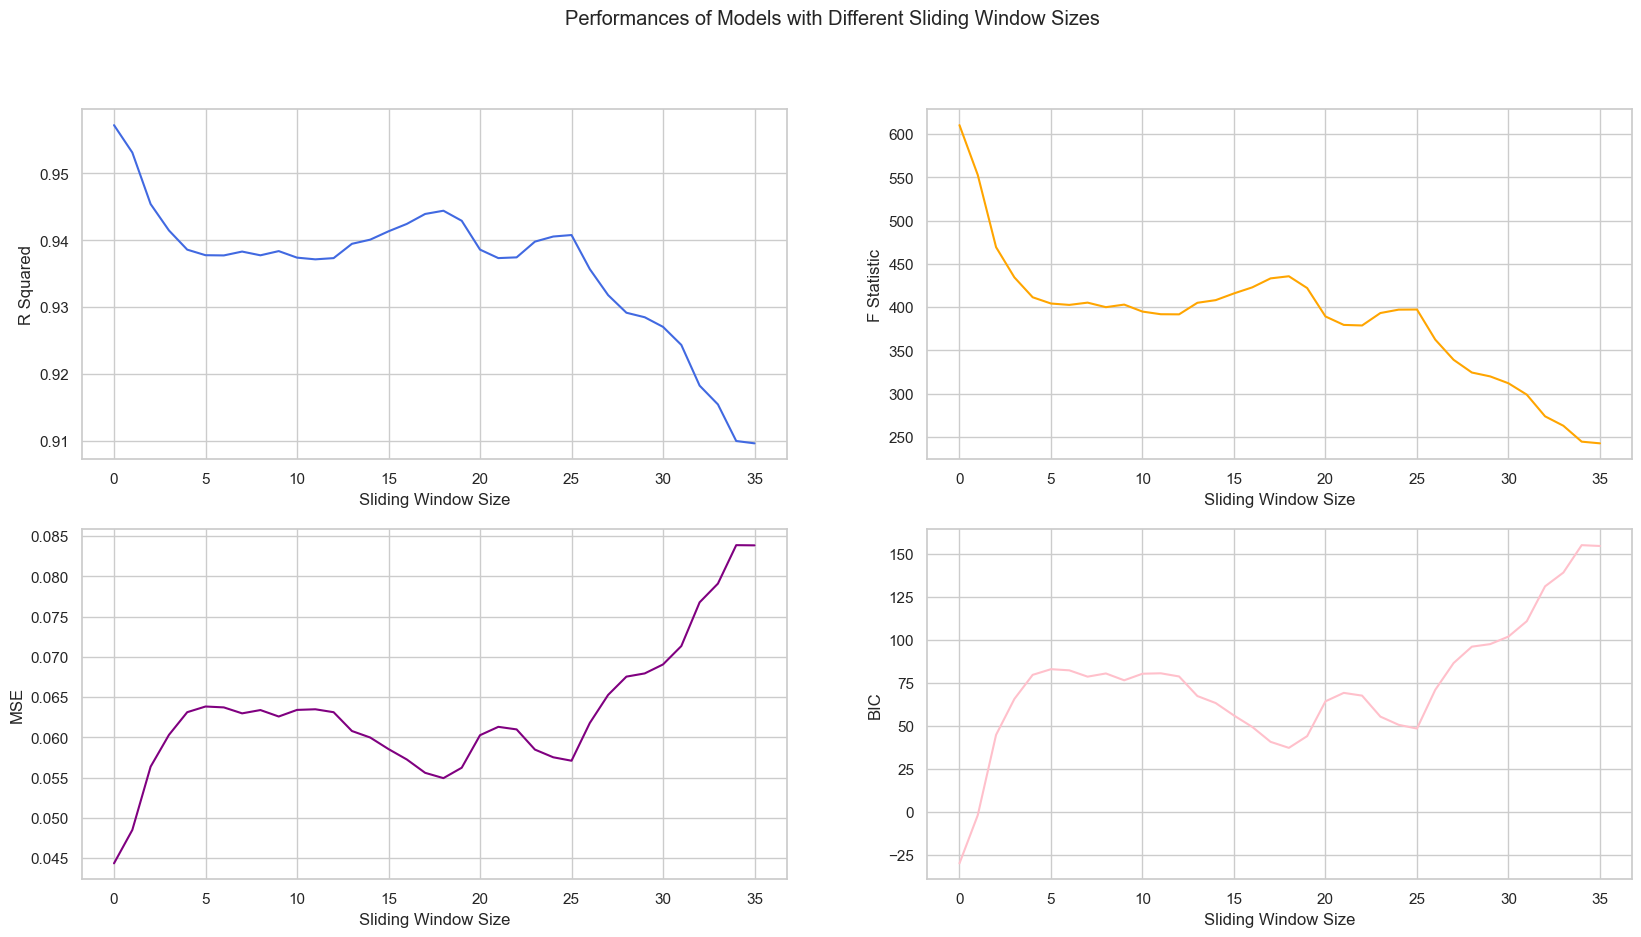

In [71]:
_, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 10))
plt.suptitle("Performances of Models with Different Sliding Window Sizes")

sns.lineplot(results, x="k", y="R Squared", ax=axes[0, 0], color="royalblue")
axes[0, 0].set_xlabel("Sliding Window Size")
axes[0, 0].set_ylabel("R Squared")

sns.lineplot(results, x="k", y="F Statistic", ax=axes[0, 1], color="orange")
axes[0, 1].set_xlabel("Sliding Window Size")
axes[0, 1].set_ylabel("F Statistic")

sns.lineplot(results, x="k", y="MSE", ax=axes[1, 0], color="purple")
axes[1, 0].set_xlabel("Sliding Window Size")
axes[1, 0].set_ylabel("MSE")

sns.lineplot(results, x="k", y="BIC", ax=axes[1, 1], color="pink")
axes[1, 1].set_xlabel("Sliding Window Size")
axes[1, 1].set_ylabel("BIC")

plt.show()

We can clearly see that the model without any sliding window has the best performance across all the measurements. Considering each sample is a monthly average and economic statistics would likely to fluctuate together monthly interval, it makes sense. Moreover, metrics fluctuates and shows some bumps rather than just keeps decreasing. In particular, we can see after initial drop from 0 to 3, we see the plateouted performance between 5 to 10. After 10 month, the performance improved from 15 to around 18. Furthermore, there is another bump around 25. Therefore, we chose four $k$ values $k = 5, 10, 18, 25$ to plot fitted lines.

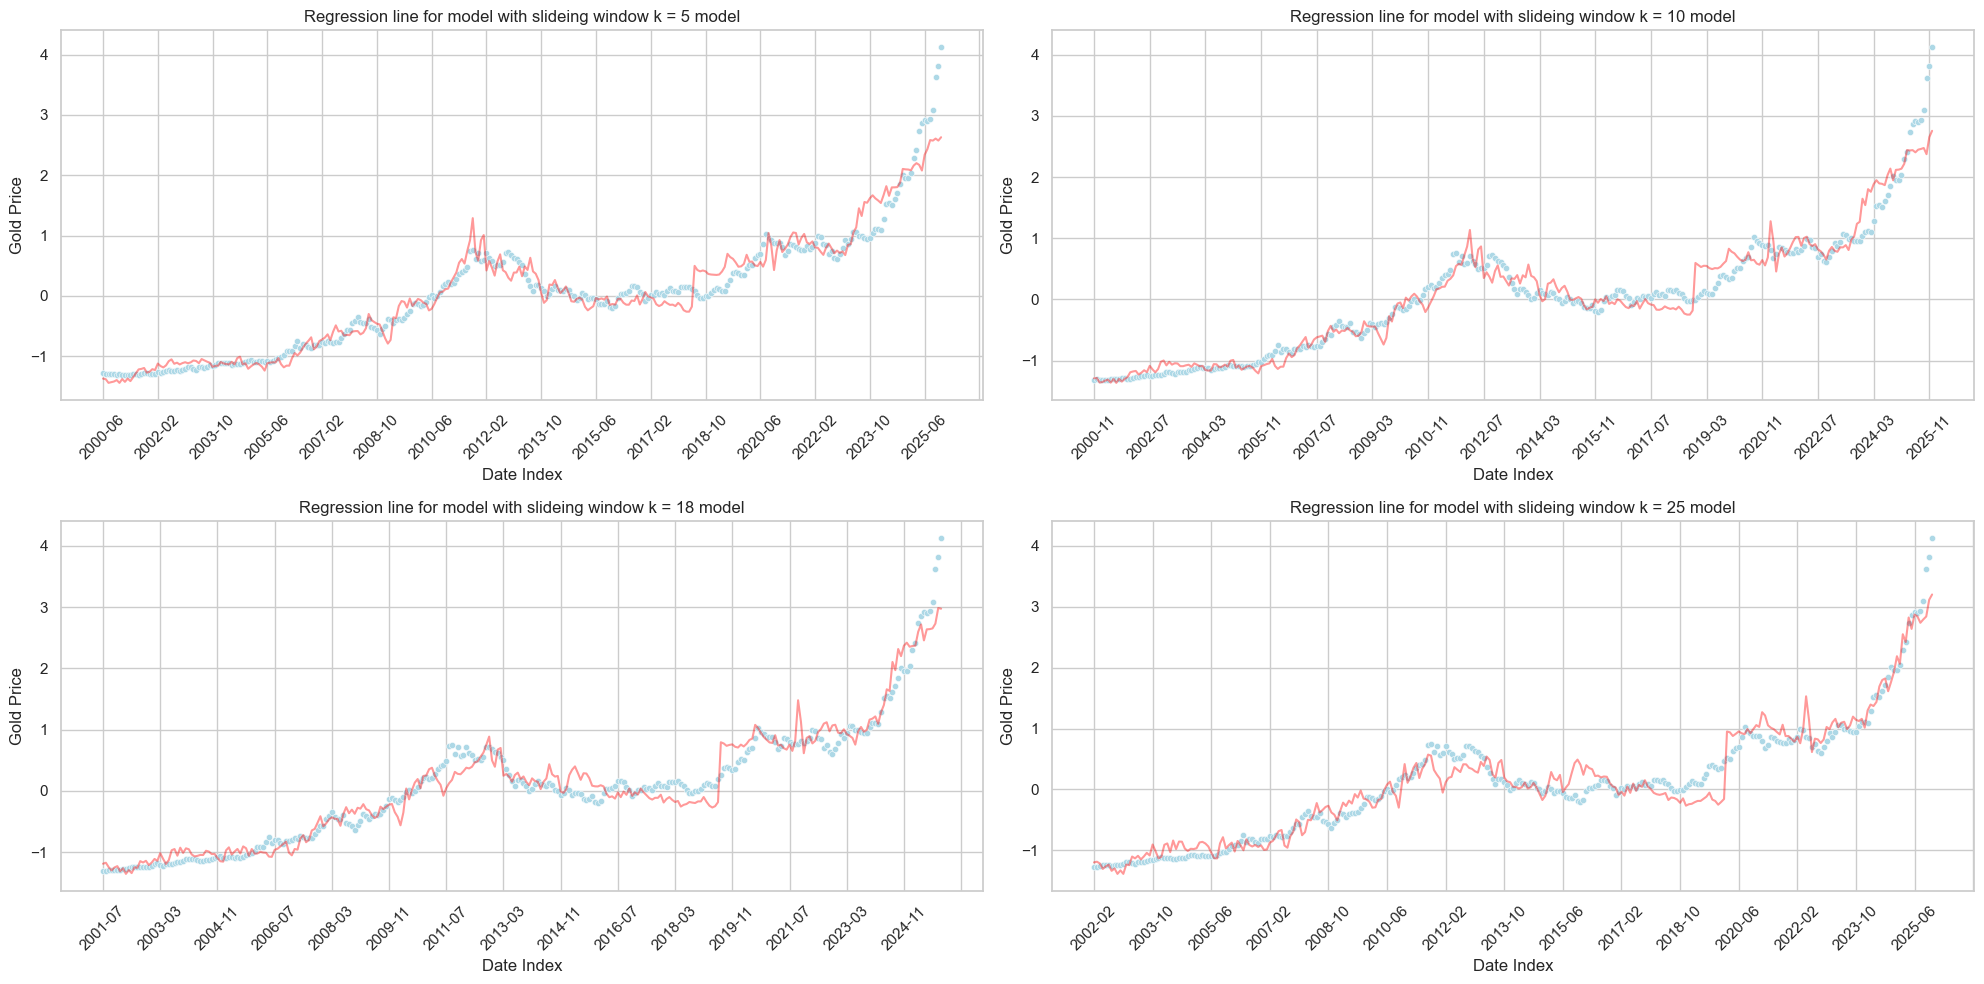

In [72]:
ks = [5, 10, 18, 25]
_, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 10))
axes = axes.flatten()

for k, ax in zip(ks, axes):
    df_k = slide_time_window(df_norm, k)
    model_k = fit_regression(df_k)

    plot_regression_line(df_k, model_k, model_name=f"model with slideing window k = {k}", ax=ax)

plt.tight_layout()
plt.show()

We can see that as sliding window becomes larger, it is more difficult to fit for samples whose date index is larger than 200.

## Before and After Pandemic

In this section, we compare how the relationships between Gold Price and variables have changed since the pandemic happened. We define the post-pandemic period as after `2020-04` (inclusive). (We label before pandemic data as `before` and after pandemic data as `after`)

In [73]:
df_before_pandemic = df_norm[df_norm.index < "2020-04"]
df_after_pandemic = df_norm[df_norm.index >= "2020-04"]

print(f"The number of samples (months): before {df_before_pandemic.shape[0]} / after {df_after_pandemic.shape[0]}")

The number of samples (months): before 243 / after 69


### Difference of Distribution

Here, we compare if distributions of Gold Prices have changed after the pandemic. First, we conduct KS-test to check if two distributions have different empirical CDF.

In [74]:
def compare_two_distribution(x1, x2, title, variable=response):
    _, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

    plt.suptitle(title)

    x_min = min(min(x1), min(x2))
    x_max = max(max(x1), max(x2))
    bins = np.linspace(x_min, x_max, 40)
    sns.histplot(x=x1, color="purple", label="before", ax=axes[0], alpha=0.6, bins=bins)
    sns.histplot(x=x2, color="royalblue", label="after", ax=axes[0], alpha=0.6, bins=bins)
    axes[0].legend()
    axes[0].set_xlabel(variable)
    axes[0].set_title(f"Histogram of {variable} from before and after pandemic data")

    sns.ecdfplot(x=x1, color="purple", label="before", ax=axes[1])
    sns.ecdfplot(x=x2, color="royalblue", label="after", ax=axes[1])
    axes[1].legend()
    axes[1].set_title(f"Empriical CDF of {variable} from before and after pandemic data")

    plt.show()

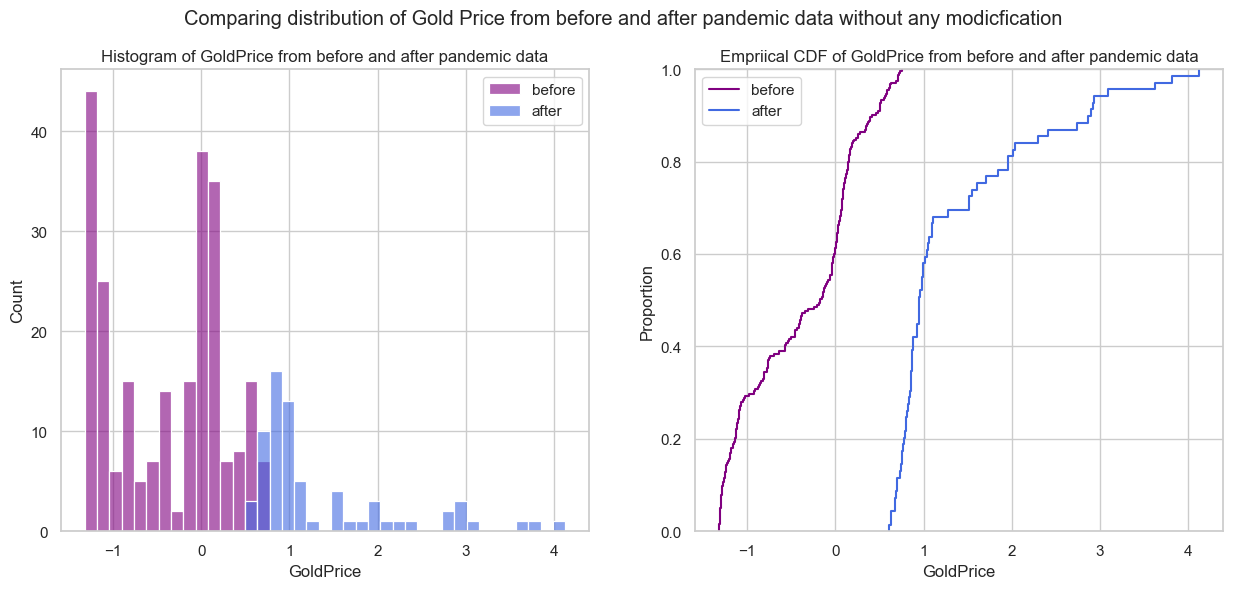

In [75]:
compare_two_distribution(df_before_pandemic[response], df_after_pandemic[response],
    title="Comparing distribution of Gold Price from before and after pandemic data without any modicfication")

In [76]:
p_value = stats.kstest(df_before_pandemic[response], df_after_pandemic[response]).pvalue
print(f"p value for KS-test between before and after pandemic Gold Price is {p_value}")

p value for KS-test between before and after pandemic Gold Price is 1.0268599017709708e-57


From the figure and statistical tests, we can clearly see that two distributions are different. However, we want to measure not only that means are just different (Gold Price became higher) but also want to check if the variability and trend has changed, which can be achieve by comparing the shape of distribution after shifting them to have same median.

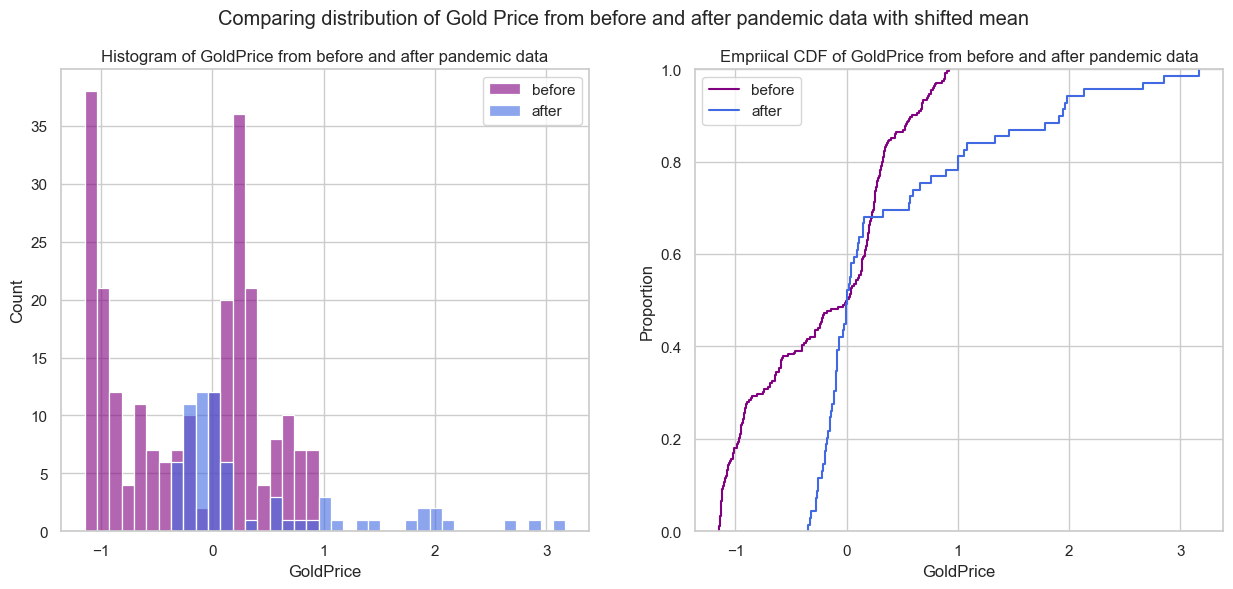

In [77]:
df_before_pandemic_shifted = df_before_pandemic.copy(deep=True)
df_after_pandemic_shifted = df_after_pandemic.copy(deep=True)

df_before_pandemic_shifted[response] = df_before_pandemic[response] - df_before_pandemic[response].median()
df_after_pandemic_shifted[response] = df_after_pandemic[response] - df_after_pandemic[response].median()
compare_two_distribution(df_before_pandemic_shifted[response], df_after_pandemic_shifted[response],
    title="Comparing distribution of Gold Price from before and after pandemic data with shifted mean")

In [78]:
p_value = stats.kstest(df_before_pandemic_shifted[response], df_after_pandemic_shifted[response]).pvalue
print(f"p value for KS-test between before and after pandemic Gold Price is {p_value}")

p value for KS-test between before and after pandemic Gold Price is 7.282007564644846e-09


While the test result show that p value became less significant but still significant enought to reject the null hypothesis that two distributions are the same.

### Difference of Residuals

Next, we compare if the distributions of residuals are different from a single linear regression model (full model). (Note that we removed outliers (>= 0.4) to get better look at distribution.)

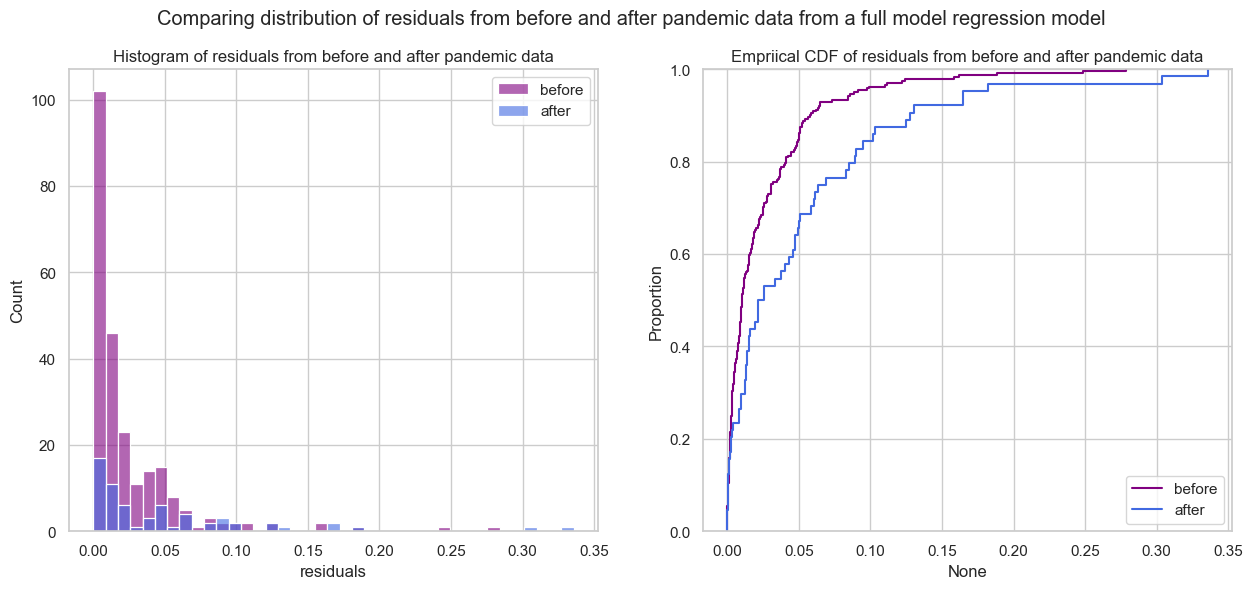

In [79]:
before_residuals = (df_before_pandemic[response] - full_model.predict(df_before_pandemic)) ** 2
after_residuals = (df_after_pandemic[response] - full_model.predict(df_after_pandemic)) ** 2

before_residuals = before_residuals[before_residuals < 0.4]
after_residuals = after_residuals[after_residuals < 0.4]

compare_two_distribution(before_residuals, after_residuals,
    title="Comparing distribution of residuals from before and after pandemic data from a full model regression model",
    variable="residuals")

In [80]:
p_value = stats.kstest(before_residuals, after_residuals).pvalue
print(f"p value for KS-test between before and after pandemic residuals from a single linear regression model is {p_value}")

p value for KS-test between before and after pandemic residuals from a single linear regression model is 0.0021697122278952477


From the figure and statistical tests, we can conclude that residuals of two distributions are different. Especially from empirical CDF, you can tell that residuals tend to be larger for after pandemic data than before pandemic data, meaning it became more difficult to predict Gold Price from variables after pandemic.

### Difference of Regression Models

Unlike in the last step where we used the same model to compare residuals, in this step, we would fit two separate linear regression models to each dataset seprately and see if there is any change in model coefficients.

In [81]:
before_pandemic_model = fit_regression(df_before_pandemic)
after_pandemic_model = fit_regression(df_after_pandemic)

before_params = before_pandemic_model.params.to_frame(name="coefficient")
before_params["period"] = ["before"] * before_params.shape[0]
after_params = after_pandemic_model.params.to_frame(name="coefficient")
after_params["period"] = ["after"] * after_params.shape[0]

coefficients = pd.concat([before_params, after_params], axis=0).reset_index(names="covariate")
coefficients

,covariate,coefficient,period
0,Intercept,-0.162652,before
1,UnemploymentRate,0.131692,before
2,TopTaxBracketThreshold,0.351326,before
3,InflationRate,0.018170,before
4,USDollarIndex,0.057832,before
5,RealInterestRate,0.116489,before
6,FederalFundsRate,0.039301,before
7,TreasuryYield,-0.347442,before
8,ConsumerConfidenceIndex,0.062902,before
9,RecessionIndicator,0.009459,before


To make figure looks more interpretable, we applied squared root for each coefficient (for negative coefficient, we took squared root to absolute value and recover sign)

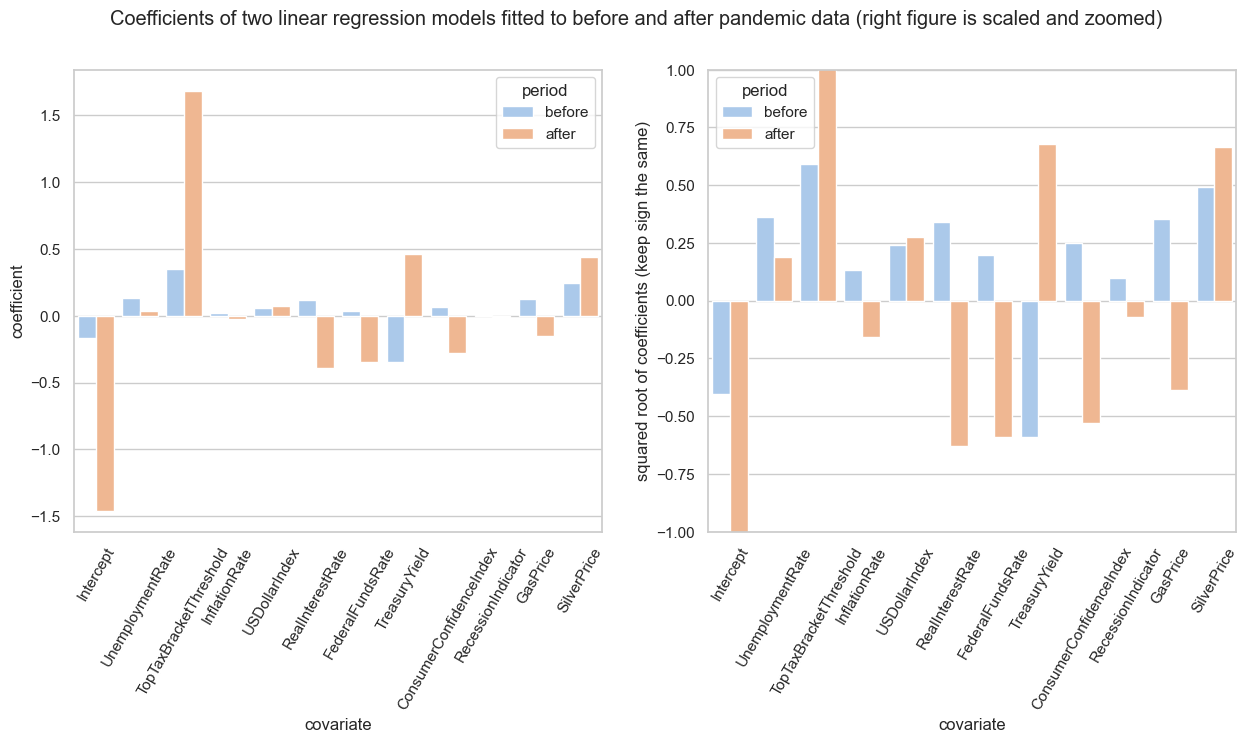

In [82]:
_, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

plt.suptitle("Coefficients of two linear regression models fitted to before and after pandemic data (right figure is scaled and zoomed)")

c = coefficients["coefficient"].values
coefficients["sqrt_coefficient"] = np.where(c <= 0, -np.sqrt(np.abs(c)), np.sqrt(np.abs(c)))

sns.barplot(coefficients, x="covariate", y="coefficient", hue="period", width=0.8, ax=axes[0])
axes[0].tick_params(axis="x", rotation=60)

sns.barplot(coefficients, x="covariate", y="sqrt_coefficient", hue="period", width=0.8, ax=axes[1])
axes[1].tick_params(axis="x", rotation=60)
axes[1].set_ylim(-1.0, 1.0)
axes[1].set_ylabel("squared root of coefficients (keep sign the same)")

plt.show()

You can see the coefficients are totally different and especially, you can see the huge different in `TopTaxBracketThreshold`. However, the analysis below shows that this variable might be just a indicator if data came from before or after pandemic.

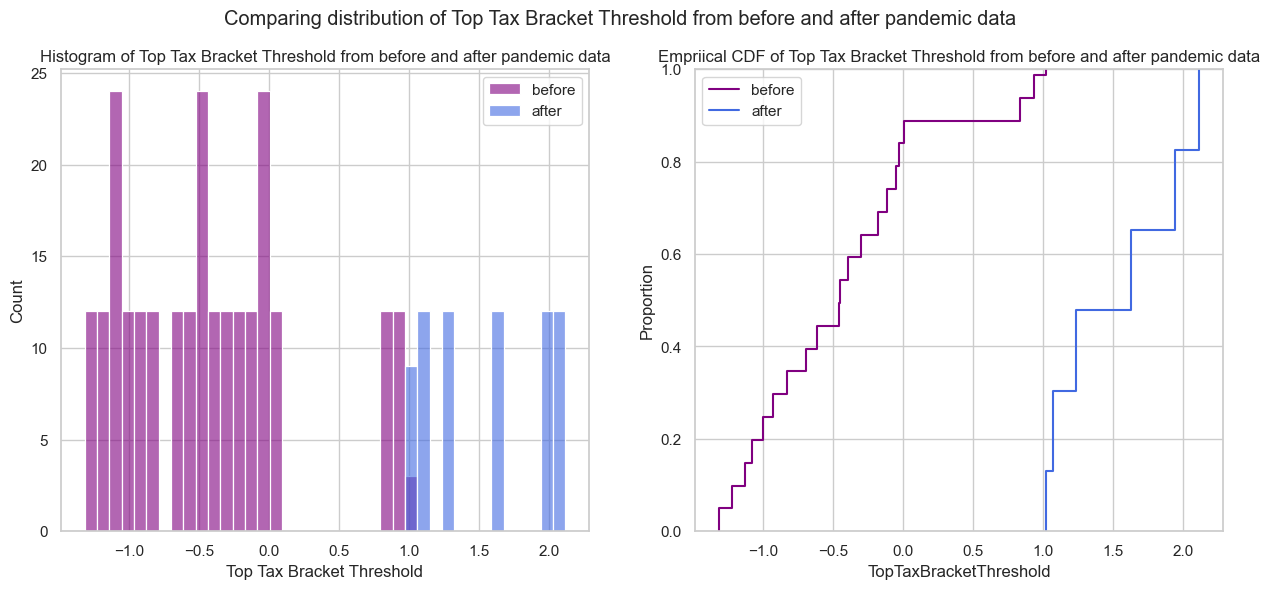

In [83]:
compare_two_distribution(df_before_pandemic["TopTaxBracketThreshold"], df_after_pandemic["TopTaxBracketThreshold"],
    title="Comparing distribution of Top Tax Bracket Threshold from before and after pandemic data ",
    variable="Top Tax Bracket Threshold")

### PCA

Here, we apply PCA to the dataset and tries to figure out if principal components can distinguish between before and after pandemic data.

In [84]:
X = df_norm.values.T / np.sqrt(df_norm.shape[0])
X.shape

(12, 312)

In [85]:
def apply_PCA(X, k):
    U, s, Vt = np.linalg.svd(X)
    beta = np.dot(U.T, X)
    return beta[:k, :]

In [86]:
k = 3

components = apply_PCA(X, k).T
components = pd.DataFrame(components, columns=[f"component_{i+1}" for i in range(k)], index=df_norm.index)
df_components = pd.concat([df_norm, components], axis=1)
df_components["period"] = ["before" if x < "2020-04" else "after" for x in df_components.index]
df_components.head(5)

,GoldPrice,UnemploymentRate,TopTaxBracketThreshold,InflationRate,USDollarIndex,RealInterestRate,FederalFundsRate,TreasuryYield,ConsumerConfidenceIndex,RecessionIndicator,GasPrice,SilverPrice,component_1,component_2,component_3,period
Date,,,,,,,,,,,,,,,,
2000-01,-1.286260,-0.844380,-1.314997,0.065467,1.079627,2.618869,0.969256,2.506151,2.163459,-0.408040,-1.772932,-1.172750,0.289984,-0.005894,-0.014422,before
2000-02,-1.264958,-0.792905,-1.314997,0.353152,1.149037,2.739402,1.851068,2.536823,2.113153,-0.384037,-1.705028,-1.204970,0.306390,0.021163,-0.025084,before
2000-03,-1.283422,-0.844380,-1.314997,0.698375,1.106864,2.653389,1.846169,2.360461,1.811337,-0.384037,-1.479536,-1.238060,0.293305,0.033836,-0.033842,before
2000-04,-1.292606,-0.947329,-1.314997,0.295615,1.519810,2.373678,2.037228,2.061413,1.962242,-0.408040,-1.476974,-1.238931,0.292910,0.028915,-0.004175,before
2000-05,-1.298775,-0.844380,-1.314997,0.353152,1.396805,2.559340,2.037228,2.283782,2.070041,-0.384037,-1.583314,-1.246768,0.302676,0.026722,-0.013209,before


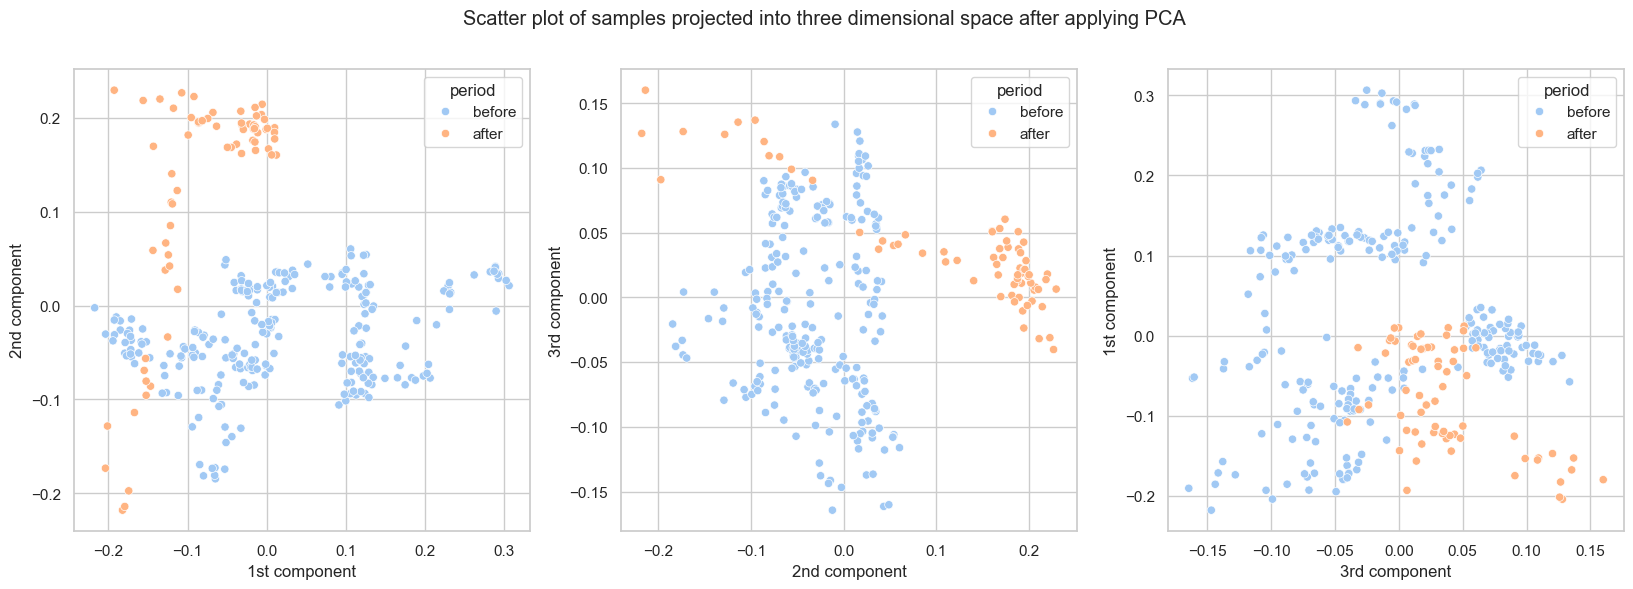

In [87]:
_, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 6))

plt.suptitle("Scatter plot of samples projected into three dimensional space after applying PCA")

sns.scatterplot(df_components, x="component_1", y="component_2", hue="period", ax=axes[0])
axes[0].set_xlabel("1st component")
axes[0].set_ylabel("2nd component")

sns.scatterplot(df_components, x="component_2", y="component_3", hue="period", ax=axes[1])
axes[1].set_xlabel("2nd component")
axes[1].set_ylabel("3rd component")

sns.scatterplot(df_components, x="component_3", y="component_1", hue="period", ax=axes[2])
axes[2].set_xlabel("3rd component")
axes[2].set_ylabel("1st component")

plt.show()

We can see that the second component is strongly related to the period and make two groups of samples almost linearly separable.

## Conclusion

Overall, our key takeaway from our analysis is that movements in gold prices can reflect broader investor confidence in the economic environment. When economic indicators signal instability or uncertainty, investors often turn to gold as a safer store of value. The long term upward trend in gold prices and its sensitivity to macroeconomic conditions highlight their role as a widely recognized safe haven asset in financial markets.